<a href="https://colab.research.google.com/github/Isaq0711/processamento-sinais-I/blob/main/aula_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AP7 — Projeto de Filtros IIR
**GELE7317 — Processamento de Sinais I** — Prof. Rafael S. Chaves

Projeto de filtros IIR a partir de **blocos básicos de 2ª ordem** (passa-baixas, passa-altas,
passa-faixas e notch), associações em cascata e em paralelo, quantização dos coeficientes e
aplicação à remoção de interferências de um sinal de áudio (`handel.wav`).

> Dados necessários em `dados/`: apenas `handel.wav` (Questão 5). As Questões 1 a 4 não usam arquivos.
> Rode as células em ordem: as funções do Setup são usadas em todas as questões.

## Método de projeto dos blocos de 2ª ordem

Para uma frequência de referência $f_c$ e frequência de amostragem $f_s$, define-se
$\omega_c = 2\pi f_c/f_s$. Em todos os blocos, os **polos** são complexos conjugados de raio $r$
e ângulo $\omega_c$, $p_{1,2}=r\,e^{\pm j\omega_c}$, e os **zeros** são colocados sobre a
circunferência unitária, onde se deseja anular a resposta. Com $(z-p_1)(z-p_2)=z^2+m_1z+m_2$:

$$m_1=-2r\cos\omega_c,\qquad m_2=r^2 .$$

| Bloco | Zeros | $H(z)$ (antes da normalização) | Normalização ($H_2=H/|H(z_0)|$) |
|---|---|---|---|
| Passa-baixas | $z=-1$ (duplo, $\omega=\pi$) | $\dfrac{(z+1)^2}{z^2+m_1z+m_2}$ | em $z_0=1$: $H(1)=\dfrac{4}{1+m_1+m_2}$ |
| Passa-altas | $z=+1$ (duplo, $\omega=0$) | $\dfrac{(z-1)^2}{z^2+m_1z+m_2}$ | em $z_0=-1$: $H(-1)=\dfrac{4}{1-m_1+m_2}$ |
| Passa-faixas | $z=\pm1$ | $\dfrac{z^2-1}{z^2+m_1z+m_2}$ | em $z_0=e^{j\omega_c}$ |
| Notch | $z=e^{\pm j\omega_c}$ | $\dfrac{z^2-2\cos\omega_c\,z+1}{z^2+m_1z+m_2}$ | em $z_0=1$ |

Como $|p_{1,2}|=r<1$, todos os blocos são estáveis. Nos blocos passa-baixas e passa-altas, $f_c$
é o **ângulo dos polos** (posição do pico de ressonância); a frequência de −3 dB é medida
numericamente.


## Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import freqz, sosfilt, sosfiltfilt, sos2tf, lfilter
from scipy.fft import fft, fftfreq
from scipy.optimize import least_squares, brentq
from IPython.display import Audio, display
import os

PASTA_DADOS = "dados"   # handel.wav deve estar nesta pasta

# No Google Colab, use o bloco abaixo para enviar o arquivo de dados:
# from google.colab import files
# uploaded = files.upload()  # selecione handel.wav
# PASTA_DADOS = "."

FS = 20000.0            # frequência de amostragem das Questões 1 a 4 (Hz)

In [ ]:
def calculate_spectrum(signal, sampling_frequency, single_sided=True):
    # Função fornecida pelo professor (repositório gele7317-proc-sin):
    # espectro de amplitude 1/N * |FFT|.
    N = len(signal)
    T = 1.0 / sampling_frequency
    yf = fft(signal)
    if single_sided:
        xf = fftfreq(N, T)[:N//2]
        amplitudes = 1.0/N * np.abs(yf[0:N//2])
    else:
        xf = fftfreq(N, T)
        amplitudes = 1.0/N * np.abs(yf)
    return xf, amplitudes


def ler_wav(nome_arquivo):
    fs, x = wavfile.read(os.path.join(PASTA_DADOS, nome_arquivo))
    if x.ndim > 1:
        x = x[:, 0]
    if np.issubdtype(x.dtype, np.integer):
        x = x.astype(np.float64) / np.iinfo(x.dtype).max
    else:
        x = x.astype(np.float64)
    return fs, x


def tocar(x, fs):
    display(Audio(x, rate=fs))

In [ ]:
# ---------------- Blocos básicos de 2ª ordem ----------------
def projetar_bloco(tipo, fc, r, fs):
    # Retorna (b, a): H(z) = (b0 + b1 z^-1 + b2 z^-2) / (1 + a1 z^-1 + a2 z^-2).
    wc = 2 * np.pi * fc / fs
    m1, m2 = -2 * r * np.cos(wc), r ** 2
    a = np.array([1.0, m1, m2])
    if tipo == "lpf":                       # zeros duplos em z = -1; ganho unitário em z = 1
        b = np.array([1.0, 2.0, 1.0]);  ganho = (1 + m1 + m2) / 4
    elif tipo == "hpf":                     # zeros duplos em z = +1; ganho unitário em z = -1
        b = np.array([1.0, -2.0, 1.0]); ganho = (1 - m1 + m2) / 4
    elif tipo == "bpf":                     # zeros em z = +-1; ganho unitário em wc
        b = np.array([1.0, 0.0, -1.0])
        ganho = 1 / abs(freqz(b, a, worN=[wc])[1][0])
    elif tipo == "notch":                   # zeros em e^{+-j wc}; ganho unitário em z = 1
        b = np.array([1.0, -2 * np.cos(wc), 1.0]); ganho = (1 + m1 + m2) / (2 - 2 * np.cos(wc))
    else:
        raise ValueError("tipo inválido")
    return ganho * b, a


def combinar_cascata(blocos):
    b_tot, a_tot = np.array([1.0]), np.array([1.0])
    for b, a in blocos:
        b_tot, a_tot = np.convolve(b_tot, b), np.convolve(a_tot, a)
    return b_tot, a_tot


def combinar_paralelo(blocos):
    a_tot = np.array([1.0])
    for _, a in blocos:
        a_tot = np.convolve(a_tot, a)
    b_tot = np.zeros(len(a_tot))
    for i, (b, _) in enumerate(blocos):
        resto = np.array([1.0])
        for j, (_, a) in enumerate(blocos):
            if j != i:
                resto = np.convolve(resto, a)
        termo = np.convolve(b, resto)
        b_tot[:len(termo)] += termo
    return b_tot, a_tot


def zeros_polos(b, a):
    n = max(len(b), len(a))
    b = np.pad(np.asarray(b, float), (0, n - len(b)))
    a = np.pad(np.asarray(a, float), (0, n - len(a)))
    return np.roots(b), np.roots(a)


def resposta(b, a, f, fs):
    return freqz(b, a, worN=f, fs=fs)[1]


def em_db(H, piso=-120.0):
    return np.maximum(20 * np.log10(np.abs(H) + 1e-15), piso)


def imprimir_hz(b, a, nome):
    num = " + ".join(f"({c:.6f}) z^-{k}" for k, c in enumerate(b))
    den = " + ".join(f"({c:.6f}) z^-{k}" for k, c in enumerate(a))
    print(f"{nome}:\n   H(z) = [{num}] / [{den}]")


def desenhar_pz(ax, zeros, polos, cor_z="k", cor_p="tab:red", rotulo=None, ms=8):
    theta = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta), "k--", lw=0.7)
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
    if len(zeros):
        ax.plot(zeros.real, zeros.imag, "o", mfc="none", mec=cor_z, ms=ms)
    if len(polos):
        ax.plot(polos.real, polos.imag, "x", color=cor_p, ms=ms, label=rotulo)
    ax.set_aspect("equal")
    ax.set_xlabel("Re(z)"); ax.set_ylabel("Im(z)")
    ax.grid(True, alpha=0.3)


def bordas_3db(f, m):
    # Frequências (com interpolação linear) em que |H| cruza pico/sqrt(2).
    alvo = m.max() / np.sqrt(2)
    idx = np.where(m >= alvo)[0]
    i0, i1 = idx[0], idx[-1]
    lo = f[i0] if i0 == 0 else np.interp(alvo, [m[i0 - 1], m[i0]], [f[i0 - 1], f[i0]])
    hi = f[i1] if i1 == len(f) - 1 else np.interp(alvo, [m[i1 + 1], m[i1]], [f[i1 + 1], f[i1]])
    return lo, hi

## Questão 1 — Blocos básicos de 2ª ordem ($f_s = 20\,000$ Hz)

Para cada bloco: função de transferência, resposta em frequência (módulo e fase), diagrama de polos e zeros
e efeito da variação de $r$ (seletividade, estabilidade e largura de banda). A tabela numérica de cada
caso mostra, para cada $r$, o pico de ganho e as frequências de −3 dB; a teoria prevê, para o passa-faixas
e o notch, uma largura de banda $B\approx(1-r)\,f_s/\pi$.


In [ ]:
VALORES_R = [0.5, 0.7, 0.9, 0.95, 0.99]
R_NOMINAL = 0.9
F_PLOT = np.linspace(0, FS / 2, 8192)


def estudo_r(tipo, fc, valores_r, fs, titulo):
    cores = plt.cm.viridis(np.linspace(0.05, 0.9, len(valores_r)))
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.8))
    print(f"{'r':>5} {'|p|':>5} {'pico (dB)':>10} {'f_pico (Hz)':>12}   medidas")
    for r, cor in zip(valores_r, cores):
        b, a = projetar_bloco(tipo, fc, r, fs)
        H = resposta(b, a, F_PLOT, fs); m = np.abs(H)
        ax1.plot(F_PLOT, em_db(H), color=cor, label=f"r = {r}")
        ax2.plot(F_PLOT, np.unwrap(np.angle(H)), color=cor)
        z, p = zeros_polos(b, a)
        ax3.plot(p.real, p.imag, "x", color=cor, ms=9)
        ip = np.argmax(m)
        if tipo == "lpf":
            extra = f"f(-3 dB) = {F_PLOT[np.where(m >= 1/np.sqrt(2))[0][-1]]:7.1f} Hz"
        elif tipo == "hpf":
            extra = f"f(-3 dB) = {F_PLOT[np.where(m >= 1/np.sqrt(2))[0][0]]:7.1f} Hz"
        elif tipo == "bpf":
            lo, hi = bordas_3db(F_PLOT, m)
            extra = f"banda -3 dB: {lo:7.1f} a {hi:7.1f} Hz (B = {hi-lo:6.1f} Hz; teoria (1-r)fs/pi = {(1-r)*fs/np.pi:6.1f})"
        else:
            idx = np.where(m < 1/np.sqrt(2))[0]
            lo, hi = F_PLOT[idx[0]], F_PLOT[idx[-1]]
            extra = f"rejeição -3 dB: {lo:7.1f} a {hi:7.1f} Hz (B = {hi-lo:6.1f} Hz; teoria (1-r)fs/pi = {(1-r)*fs/np.pi:6.1f})"
        print(f"{r:5.2f} {np.max(np.abs(p)):5.2f} {20*np.log10(m[ip]):10.2f} {F_PLOT[ip]:12.1f}   {extra}")
    ax3.plot(z.real, z.imag, "o", mfc="none", mec="k", ms=9)
    theta = np.linspace(0, 2 * np.pi, 400)
    ax3.plot(np.cos(theta), np.sin(theta), "k--", lw=0.7)
    ax3.axhline(0, color="gray", lw=0.5); ax3.axvline(0, color="gray", lw=0.5)
    ax3.set_aspect("equal"); ax3.set_title("Polos (×, um por r) e zeros (○)")
    ax3.set_xlabel("Re(z)"); ax3.set_ylabel("Im(z)"); ax3.grid(True, alpha=0.3)
    ax1.axvline(fc, color="gray", ls=":", lw=0.8)
    ax1.set_ylim(-60, 35); ax1.set_xlabel("Frequência (Hz)"); ax1.set_ylabel("Módulo (dB)")
    ax1.set_title(f"{titulo} — módulo"); ax1.legend(fontsize=8); ax1.grid(True, alpha=0.3)
    ax2.set_xlabel("Frequência (Hz)"); ax2.set_ylabel("Fase (rad)")
    ax2.set_title(f"{titulo} — fase"); ax2.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()

### (a) Passa-baixas, $f_c = 1000$ Hz

omega_c = 0.31416 rad/amostra | m1 = -1.711902 | m2 = 0.810000 | ganho = 0.024525
Passa-baixas (r = 0.9):
   H(z) = [(0.024525) z^-0 + (0.049049) z^-1 + (0.024525) z^-2] / [(1.000000) z^-0 + (-1.711902) z^-1 + (0.810000) z^-2]
    r   |p|  pico (dB)  f_pico (Hz)   medidas
 0.50  0.50      -0.00          0.0   f(-3 dB) =  1648.2 Hz
 0.70  0.70      -0.00          0.0   f(-3 dB) =  1368.6 Hz
 0.90  0.90       4.27        937.6   f(-3 dB) =  1498.0 Hz
 0.95  0.95       9.81        985.2   f(-3 dB) =  1526.1 Hz
 0.99  0.99      23.74        999.9   f(-3 dB) =  1534.6 Hz


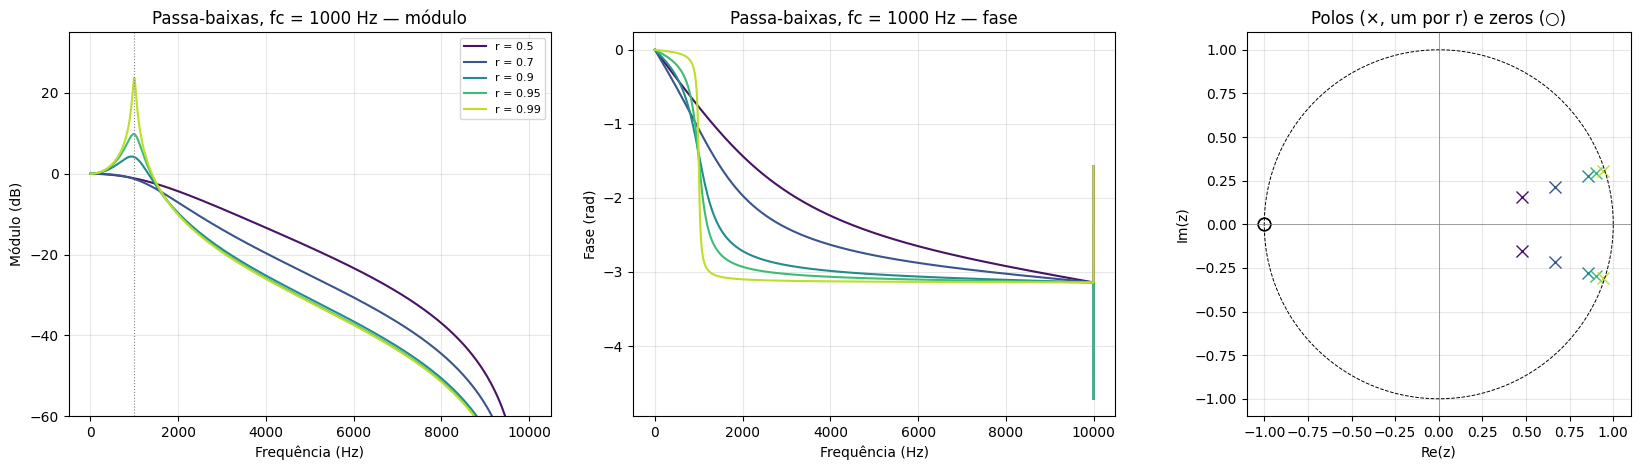

In [ ]:
bq, aq = projetar_bloco("lpf", 1000, R_NOMINAL, FS)
print(f"omega_c = {2*np.pi*1000/FS:.5f} rad/amostra | m1 = {aq[1]:.6f} | m2 = {aq[2]:.6f} | ganho = {bq[0]:.6f}")
imprimir_hz(bq, aq, f"Passa-baixas (r = {R_NOMINAL})")
estudo_r("lpf", 1000, VALORES_R, FS, "Passa-baixas, fc = 1000 Hz")

### (b) Passa-altas, $f_c = 2000$ Hz

omega_c = 0.62832 rad/amostra | m1 = -1.456231 | m2 = 0.810000 | ganho = 0.816558
Passa-altas (r = 0.9):
   H(z) = [(0.816558) z^-0 + (-1.633115) z^-1 + (0.816558) z^-2] / [(1.000000) z^-0 + (-1.456231) z^-1 + (0.810000) z^-2]
    r   |p|  pico (dB)  f_pico (Hz)   medidas
 0.50  0.50       0.00      10000.0   f(-3 dB) =  3058.2 Hz
 0.70  0.70       0.96       3218.2   f(-3 dB) =  1841.0 Hz
 0.90  0.90       9.17       2086.4   f(-3 dB) =  1358.8 Hz
 0.95  0.95      15.22       2020.5   f(-3 dB) =  1323.4 Hz
 0.99  0.99      29.32       2001.0   f(-3 dB) =  1313.6 Hz


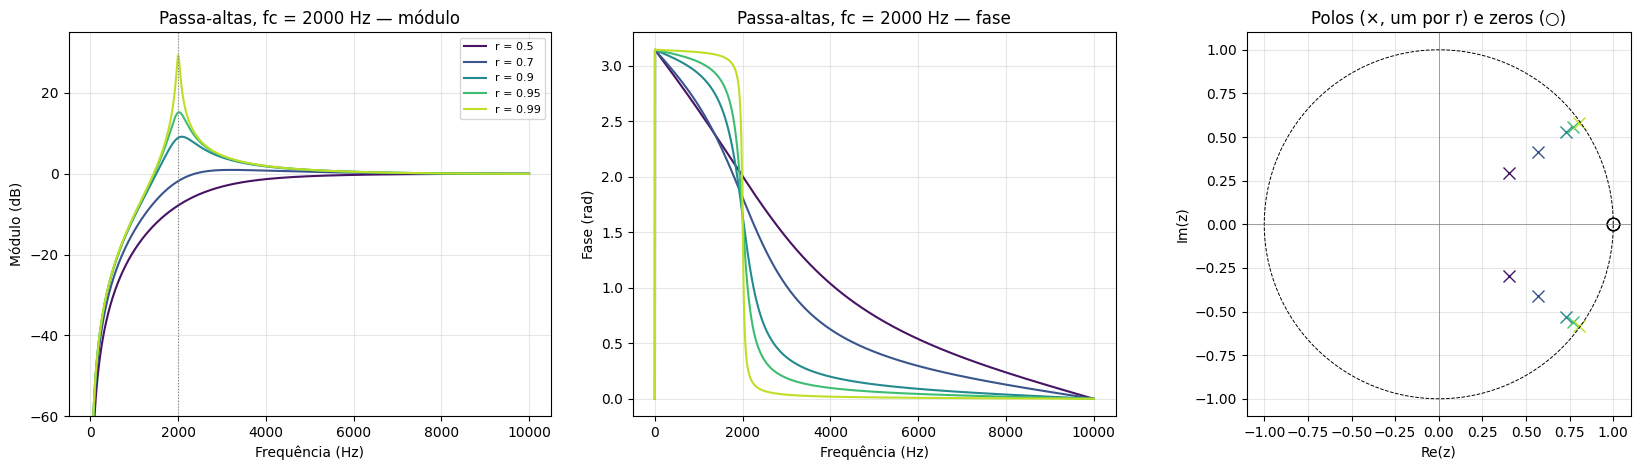

In [ ]:
bq, aq = projetar_bloco("hpf", 2000, R_NOMINAL, FS)
print(f"omega_c = {2*np.pi*2000/FS:.5f} rad/amostra | m1 = {aq[1]:.6f} | m2 = {aq[2]:.6f} | ganho = {bq[0]:.6f}")
imprimir_hz(bq, aq, f"Passa-altas (r = {R_NOMINAL})")
estudo_r("hpf", 2000, VALORES_R, FS, "Passa-altas, fc = 2000 Hz")

### (c) Passa-faixas, $f_c = 7000$ Hz

In [ ]:
bq, aq = projetar_bloco("bpf", 7000, R_NOMINAL, FS)
print(f"omega_c = {2*np.pi*7000/FS:.5f} rad/amostra | m1 = {aq[1]:.6f} | m2 = {aq[2]:.6f} | ganho = {bq[0]:.6f}")
imprimir_hz(bq, aq, f"Passa-faixas (r = {R_NOMINAL})")
estudo_r("bpf", 7000, VALORES_R, FS, "Passa-faixas, fc = 7000 Hz")

### (d) Notch, $f_c = 3000$ Hz

In [ ]:
bq, aq = projetar_bloco("notch", 3000, R_NOMINAL, FS)
print(f"omega_c = {2*np.pi*3000/FS:.5f} rad/amostra | m1 = {aq[1]:.6f} | m2 = {aq[2]:.6f} | ganho = {bq[0]:.6f}")
imprimir_hz(bq, aq, f"Notch (r = {R_NOMINAL})")
estudo_r("notch", 3000, VALORES_R, FS, "Notch, fc = 3000 Hz")

## Questão 2 — Passa-faixas $f_{c1}=6000$ Hz, $f_{c2}=8000$ Hz por **cascata** de blocos de 2ª ordem

A banda passante entre $f_{c1}$ e $f_{c2}$ é obtida pela cascata de um bloco **passa-altas** em $f_{c1}$ com um
bloco **passa-baixas** em $f_{c2}$:
$$H(z)=H_{HP}(z;f_{c1},r)\,H_{LP}(z;f_{c2},r),$$
um filtro de 4ª ordem (4 polos, zeros duplos em $z=1$ e $z=-1$). Como $f_c$ de cada bloco é o ângulo dos polos
(e não a frequência de −3 dB), analisa-se também uma versão com os ângulos dos polos **ajustados** numericamente para que
as bordas de −3 dB (em relação ao pico da banda) caiam exatamente em 6000 e 8000 Hz, com ganho de pico normalizado a 0 dB.


In [ ]:
F_FINO = np.linspace(0, FS / 2, 20001)
R_Q2 = 0.6

def cascata_q2(f_hp, f_lp, r_hp, r_lp):
    bh, ah = projetar_bloco("hpf", f_hp, r_hp, FS)
    bl, al = projetar_bloco("lpf", f_lp, r_lp, FS)
    return [(bh, ah), (bl, al)]


def medidas_passafaixas(b, a, f=F_FINO):
    m = np.abs(resposta(b, a, f, FS))
    lo, hi = bordas_3db(f, m)
    g = lambda fx: 20 * np.log10(m[np.argmin(np.abs(f - fx))] + 1e-15)
    return dict(pico_dB=20 * np.log10(m.max()), f_pico=f[np.argmax(m)], lo=lo, hi=hi, B=hi - lo,
                a3k=g(3000), a95=g(9500), em_7k=g(7000), em_6k=g(6000), em_8k=g(8000))


# Varredura de r (projeto direto: polos em 6000 e 8000 Hz)
print(f"{'r':>5} {'pico (dB)':>10} {'f_pico':>8} {'borda inf':>10} {'borda sup':>10} {'B (Hz)':>8} {'|H|(3k)':>8} {'|H|(9,5k)':>10}")
for r in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    b, a = combinar_cascata(cascata_q2(6000, 8000, r, r))
    s = medidas_passafaixas(b, a)
    print(f"{r:5.2f} {s['pico_dB']:10.2f} {s['f_pico']:8.0f} {s['lo']:10.0f} {s['hi']:10.0f} {s['B']:8.0f} {s['a3k']:8.1f} {s['a95']:10.1f}")

In [ ]:
# --- Projeto direto (A): polos dos blocos em 6000 e 8000 Hz, r = 0,6 ---
blocos_q2 = cascata_q2(6000, 8000, R_Q2, R_Q2)
b_q2, a_q2 = combinar_cascata(blocos_q2)
(bh_q2, ah_q2), (bl_q2, al_q2) = blocos_q2
imprimir_hz(bh_q2, ah_q2, "Bloco passa-altas (fc1 = 6000 Hz)")
imprimir_hz(bl_q2, al_q2, "Bloco passa-baixas (fc2 = 8000 Hz)")
imprimir_hz(b_q2, a_q2, "Cascata (projeto direto)")

# --- Projeto ajustado (B): ângulos dos polos ajustados para bordas em 6000 e 8000 Hz ---
def residuo_bordas(p):
    b, a = combinar_cascata(cascata_q2(p[0], p[1], R_Q2, R_Q2))
    m = np.abs(resposta(b, a, F_FINO, FS))
    lo, hi = bordas_3db(F_FINO, m)
    return [lo - 6000.0, hi - 8000.0]

sol = least_squares(residuo_bordas, x0=[6000.0, 8000.0], diff_step=1e-3)
f_hp_aj, f_lp_aj = sol.x
blocos_q2_aj = cascata_q2(f_hp_aj, f_lp_aj, R_Q2, R_Q2)
b_aj, a_aj = combinar_cascata(blocos_q2_aj)
b_aj = b_aj / np.max(np.abs(resposta(b_aj, a_aj, F_FINO, FS)))      # pico em 0 dB
print(f"\nAjuste: polo do bloco passa-altas em {f_hp_aj:.1f} Hz, polo do bloco passa-baixas em {f_lp_aj:.1f} Hz")
imprimir_hz(b_aj, a_aj, "Cascata (projeto ajustado, pico normalizado em 0 dB)")

for nome, (b, a) in {"direto (A)": (b_q2, a_q2), "ajustado (B)": (b_aj, a_aj)}.items():
    s = medidas_passafaixas(b, a)
    print(f"\n{nome}: pico {s['pico_dB']:.2f} dB em {s['f_pico']:.0f} Hz | bordas -3 dB: {s['lo']:.1f} a {s['hi']:.1f} Hz (B = {s['B']:.1f} Hz)"
          f" | |H| em 6/7/8 kHz: {s['em_6k']:.2f}/{s['em_7k']:.2f}/{s['em_8k']:.2f} dB | em 3 kHz: {s['a3k']:.1f} dB, em 9,5 kHz: {s['a95']:.1f} dB")
    z, p = zeros_polos(b, a)
    print(f"   polos: raio = {np.round(np.abs(p), 3)}, ângulos = {np.round(np.degrees(np.angle(p)), 1)} graus; |polo|max = {np.max(np.abs(p)):.3f} (estável)")

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.8))
for (b, a), nome, cor in [((b_q2, a_q2), "A: polos em 6000/8000 Hz", "tab:blue"),
                          ((b_aj, a_aj), "B: polos ajustados", "tab:orange")]:
    H = resposta(b, a, F_PLOT, FS)
    ax1.plot(F_PLOT, em_db(H), color=cor, label=nome)
    ax2.plot(F_PLOT, np.unwrap(np.angle(H)), color=cor)
    z, p = zeros_polos(b, a)
    ax3.plot(p.real, p.imag, "x", color=cor, ms=9, label=nome + " (polos)")
ax3.plot(z.real, z.imag, "o", mfc="none", mec="k", ms=9, label="zeros (z = ±1, duplos)")
theta = np.linspace(0, 2 * np.pi, 400); ax3.plot(np.cos(theta), np.sin(theta), "k--", lw=0.7)
ax3.axhline(0, color="gray", lw=0.5); ax3.axvline(0, color="gray", lw=0.5)
ax3.set_aspect("equal"); ax3.set_xlabel("Re(z)"); ax3.set_ylabel("Im(z)"); ax3.legend(fontsize=7); ax3.grid(True, alpha=0.3)
for fx in (6000, 8000):
    ax1.axvline(fx, color="gray", ls=":", lw=0.8)
ax1.set_ylim(-60, 10); ax1.set_xlabel("Frequência (Hz)"); ax1.set_ylabel("Módulo (dB)")
ax1.set_title("Passa-faixas em cascata — módulo"); ax1.legend(fontsize=8); ax1.grid(True, alpha=0.3)
ax2.set_xlabel("Frequência (Hz)"); ax2.set_ylabel("Fase (rad)"); ax2.set_title("Passa-faixas em cascata — fase"); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### Comparação com o passa-faixas de bloco único da Questão 1(c)

r do bloco único com B = 2000 Hz: r = 0.7138
filtro                              pico dB  f_pico    bordas -3 dB (Hz)      B  |H|(1k)  |H|(3k) |H|(9,5k)
Bloco único (Q1c, 2ª ordem)            0.06    6876      5773 a    7773   2000    -23.5    -12.9     -18.6
Cascata A (4ª ordem)                   0.81    6470      5260 a    7673   2413    -36.8    -15.9     -28.5
Cascata B (4ª ordem, ajustada)         0.00    7096      6000 a    8000   2000    -40.9    -20.3     -27.2


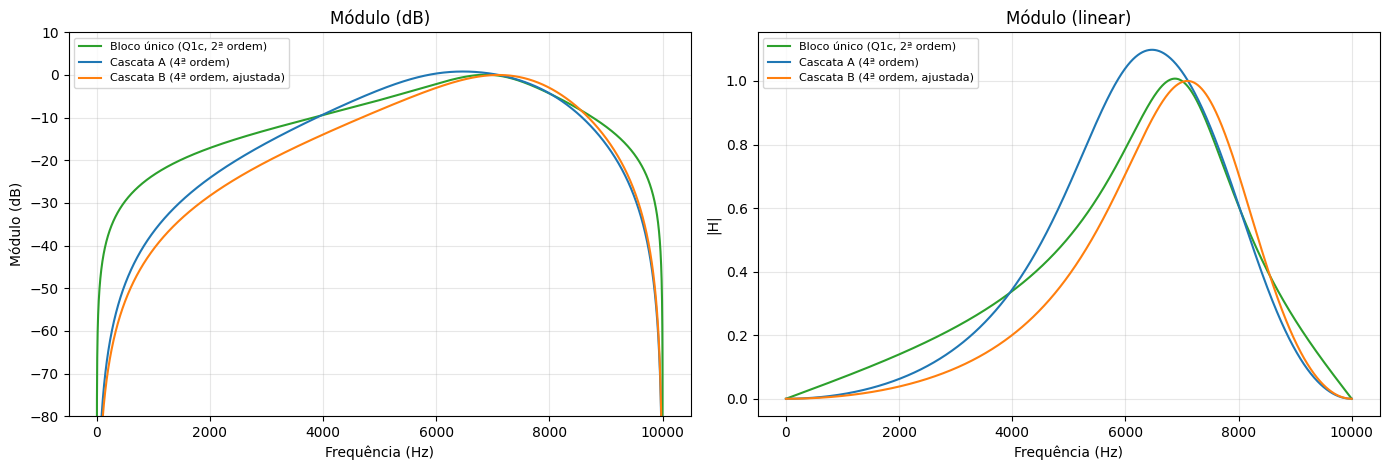

In [ ]:
# Bloco único em 7000 Hz com r escolhido para a mesma largura de banda (-3 dB) da cascata ajustada
B_ALVO = medidas_passafaixas(b_aj, a_aj)["B"]
def erro_largura(r):
    b, a = projetar_bloco("bpf", 7000, r, FS)
    return medidas_passafaixas(b, a)["B"] - B_ALVO
r_bpf = brentq(erro_largura, 0.3, 0.95)
b_bpf, a_bpf = projetar_bloco("bpf", 7000, r_bpf, FS)
print(f"r do bloco único com B = {B_ALVO:.0f} Hz: r = {r_bpf:.4f}")

comparacao = {"Bloco único (Q1c, 2ª ordem)": (b_bpf, a_bpf), "Cascata A (4ª ordem)": (b_q2, a_q2), "Cascata B (4ª ordem, ajustada)": (b_aj, a_aj)}
print(f"{'filtro':<34} {'pico dB':>8} {'f_pico':>7} {'bordas -3 dB (Hz)':>20} {'B':>6} {'|H|(1k)':>8} {'|H|(3k)':>8} {'|H|(9,5k)':>9}")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for (nome, (b, a)), cor in zip(comparacao.items(), ["tab:green", "tab:blue", "tab:orange"]):
    H = resposta(b, a, F_PLOT, FS)
    ax1.plot(F_PLOT, em_db(H), color=cor, label=nome)
    ax2.plot(F_PLOT, np.abs(H), color=cor, label=nome)
    s = medidas_passafaixas(b, a)
    g1k = 20 * np.log10(np.abs(resposta(b, a, np.array([1000.0]), FS))[0])
    print(f"{nome:<34} {s['pico_dB']:8.2f} {s['f_pico']:7.0f} {s['lo']:9.0f} a {s['hi']:7.0f} {s['B']:6.0f} {g1k:8.1f} {s['a3k']:8.1f} {s['a95']:9.1f}")
ax1.set_ylim(-80, 10); ax1.set_xlabel("Frequência (Hz)"); ax1.set_ylabel("Módulo (dB)"); ax1.set_title("Módulo (dB)")
ax2.set_xlabel("Frequência (Hz)"); ax2.set_ylabel("|H|"); ax2.set_title("Módulo (linear)")
for ax in (ax1, ax2):
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## Questão 3 — Rejeita-faixas $f_{c1}=1000$ Hz, $f_{c2}=4000$ Hz por **paralelo** de blocos de 2ª ordem

Soma de um bloco **passa-baixas** em $f_{c1}$ com um bloco **passa-altas** em $f_{c2}$:
$$H(z)=H_{LP}(z;f_{c1},r)+s\,H_{HP}(z;f_{c2},r),\qquad s=+1.$$
Em DC o ramo passa-baixas vale 1 e o passa-altas vale 0; em Nyquist ocorre o oposto, de modo que ambos
os extremos da banda são preservados. Na região intermediária os dois ramos estão atenuados e se somam
vetorialmente. A variante $s=-1$ (diferença dos ramos) é investigada na varredura de $r$.


In [ ]:
R_Q3 = 0.5

def paralelo_q3(r_lp, r_hp):
    bl, al = projetar_bloco("lpf", 1000, r_lp, FS)
    bh, ah = projetar_bloco("hpf", 4000, r_hp, FS)
    return [(bl, al), (bh, ah)]


def medidas_rejeitafaixas(b, a, f=F_FINO):
    mdb = 20 * np.log10(np.abs(resposta(b, a, f, FS)) + 1e-15)
    def faixa(lim):
        idx = np.where(mdb <= -lim)[0]
        return (f[idx[0]], f[idx[-1]]) if len(idx) else (np.nan, np.nan)
    z, p = zeros_polos(b, a)
    return dict(minimo=mdb.min(), f_min=f[np.argmin(mdb)], pico=mdb.max(), f_pico=f[np.argmax(mdb)],
                dc=mdb[0], nyq=mdb[-1], f3=faixa(3), f6=faixa(6), zeros=np.sort(np.abs(z)), polos=np.max(np.abs(p)))


# Varredura de r e do sinal s do ramo passa-altas
print(f"{'s':>3} {'r':>5} {'mín (dB)':>9} {'f_mín':>7} {'pico (dB)':>10} {'f_pico':>7}   atenuação >= 3 dB          atenuação >= 6 dB")
for s in (+1, -1):
    for r in [0.3, 0.5, 0.7, 0.9, 0.95]:
        bl, al = projetar_bloco("lpf", 1000, r, FS); bh, ah = projetar_bloco("hpf", 4000, r, FS)
        b = np.convolve(bl, ah) + s * np.convolve(bh, al); a = np.convolve(al, ah)
        m = medidas_rejeitafaixas(b, a)
        f3 = "—" if np.isnan(m['f3'][0]) else f"{m['f3'][0]:5.0f} a {m['f3'][1]:5.0f} Hz"
        f6 = "—" if np.isnan(m['f6'][0]) else f"{m['f6'][0]:5.0f} a {m['f6'][1]:5.0f} Hz"
        print(f"{s:+3d} {r:5.2f} {m['minimo']:9.1f} {m['f_min']:7.0f} {m['pico']:10.2f} {m['f_pico']:7.0f}   {f3:<24}   {f6}")

  s     r  mín (dB)   f_mín  pico (dB)  f_pico   atenuação >= 3 dB          atenuação >= 6 dB
 +1  0.30     -14.2    3680       0.00   10000    1754 a  6104 Hz            2411 a  5133 Hz
 +1  0.50      -8.8    2812       0.00    9150    1417 a  4323 Hz            2034 a  3610 Hz
 +1  0.70      -6.2    2180       3.19    4520    1309 a  3011 Hz            1982 a  2378 Hz
 +1  0.90      -5.2    2074      13.15    4040    1596 a  2634 Hz           —
 +1  0.95      -5.1    2080      19.36    4010    1638 a  2612 Hz           —
 -1  0.30      -1.5    3198       0.00    9396   —                          —
 -1  0.50      -3.3    2594       0.77    5679    2220 a  2956 Hz           —
 -1  0.70      -7.1    2314       3.82    4516    1446 a  3061 Hz            1954 a  2654 Hz
 -1  0.90     -16.7    2121      13.21    4046    1448 a  2914 Hz            1594 a  2722 Hz
 -1  0.95     -22.8    2092      19.37    4011    1466 a  2898 Hz            1584 a  2714 Hz


Ramo passa-baixas (fc1 = 1000 Hz):
   H(z) = [(0.074736) z^-0 + (0.149472) z^-1 + (0.074736) z^-2] / [(1.000000) z^-0 + (-0.951057) z^-1 + (0.250000) z^-2]
Ramo passa-altas (fc2 = 4000 Hz):
   H(z) = [(0.389754) z^-0 + (-0.779508) z^-1 + (0.389754) z^-2] / [(1.000000) z^-0 + (-0.309017) z^-1 + (0.250000) z^-2]
Paralelo (H = H_LP + H_HP):
   H(z) = [(0.464490) z^-0 + (-1.023810) z^-1 + (1.275780) z^-2 + (-0.551282) z^-3 + (0.116123) z^-4] / [(1.000000) z^-0 + (-1.260074) z^-1 + (0.793893) z^-2 + (-0.315018) z^-3 + (0.062500) z^-4]

Ganho em DC = 0.000 dB | em Nyquist = 0.000 dB | pico = 0.00 dB
Mínimo = -8.8 dB em 2812 Hz | atenuação >= 3 dB: 1417 a 4323 Hz | >= 6 dB: 2034 a 3610 Hz
Zeros da soma (módulo): [1.294 1.294 0.386 0.386] | ângulos (graus): [ 50.6 -50.6  43.3 -43.3]
Polos (módulo): [0.5 0.5 0.5 0.5] -> estável


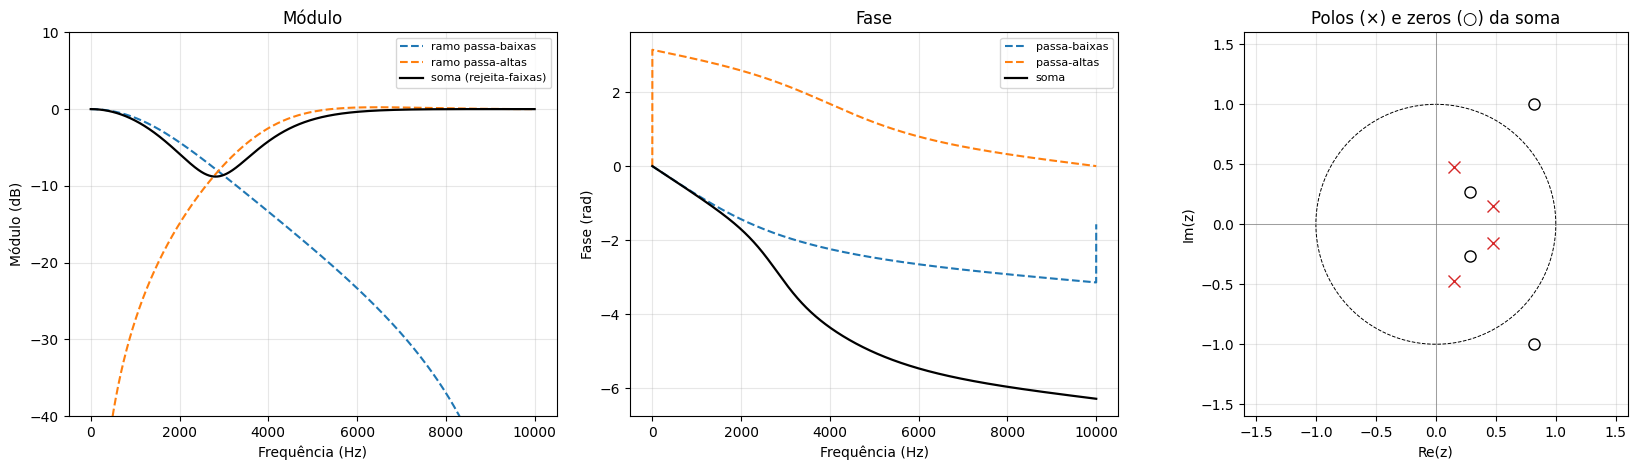

In [ ]:
# --- Projeto adotado: s = +1, r = 0,5 ---
blocos_q3 = paralelo_q3(R_Q3, R_Q3)
b_q3, a_q3 = combinar_paralelo(blocos_q3)
(bl_q3, al_q3), (bh_q3, ah_q3) = blocos_q3
imprimir_hz(bl_q3, al_q3, "Ramo passa-baixas (fc1 = 1000 Hz)")
imprimir_hz(bh_q3, ah_q3, "Ramo passa-altas (fc2 = 4000 Hz)")
imprimir_hz(b_q3, a_q3, "Paralelo (H = H_LP + H_HP)")
m3 = medidas_rejeitafaixas(b_q3, a_q3)
print(f"\nGanho em DC = {m3['dc']:.3f} dB | em Nyquist = {m3['nyq']:.3f} dB | pico = {m3['pico']:.2f} dB")
print(f"Mínimo = {m3['minimo']:.1f} dB em {m3['f_min']:.0f} Hz | atenuação >= 3 dB: {m3['f3'][0]:.0f} a {m3['f3'][1]:.0f} Hz | >= 6 dB: {m3['f6'][0]:.0f} a {m3['f6'][1]:.0f} Hz")
z3, p3 = zeros_polos(b_q3, a_q3)
print("Zeros da soma (módulo):", np.round(np.abs(z3), 3), "| ângulos (graus):", np.round(np.degrees(np.angle(z3)), 1))
print("Polos (módulo):", np.round(np.abs(p3), 3), "-> estável")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(17, 4.8))
Hl, Hh, Ht = resposta(bl_q3, al_q3, F_PLOT, FS), resposta(bh_q3, ah_q3, F_PLOT, FS), resposta(b_q3, a_q3, F_PLOT, FS)
ax1.plot(F_PLOT, em_db(Hl), "--", color="tab:blue", label="ramo passa-baixas")
ax1.plot(F_PLOT, em_db(Hh), "--", color="tab:orange", label="ramo passa-altas")
ax1.plot(F_PLOT, em_db(Ht), color="k", lw=1.6, label="soma (rejeita-faixas)")
ax1.set_ylim(-40, 10); ax1.set_xlabel("Frequência (Hz)"); ax1.set_ylabel("Módulo (dB)"); ax1.set_title("Módulo"); ax1.legend(fontsize=8); ax1.grid(True, alpha=0.3)
ax2.plot(F_PLOT, np.unwrap(np.angle(Hl)), "--", color="tab:blue", label="passa-baixas")
ax2.plot(F_PLOT, np.unwrap(np.angle(Hh)), "--", color="tab:orange", label="passa-altas")
ax2.plot(F_PLOT, np.unwrap(np.angle(Ht)), color="k", lw=1.6, label="soma")
ax2.set_xlabel("Frequência (Hz)"); ax2.set_ylabel("Fase (rad)"); ax2.set_title("Fase"); ax2.legend(fontsize=8); ax2.grid(True, alpha=0.3)
desenhar_pz(ax3, z3, p3, rotulo="polos")
ax3.set_title("Polos (×) e zeros (○) da soma"); ax3.set_xlim(-1.6, 1.6); ax3.set_ylim(-1.6, 1.6)
plt.tight_layout(); plt.show()

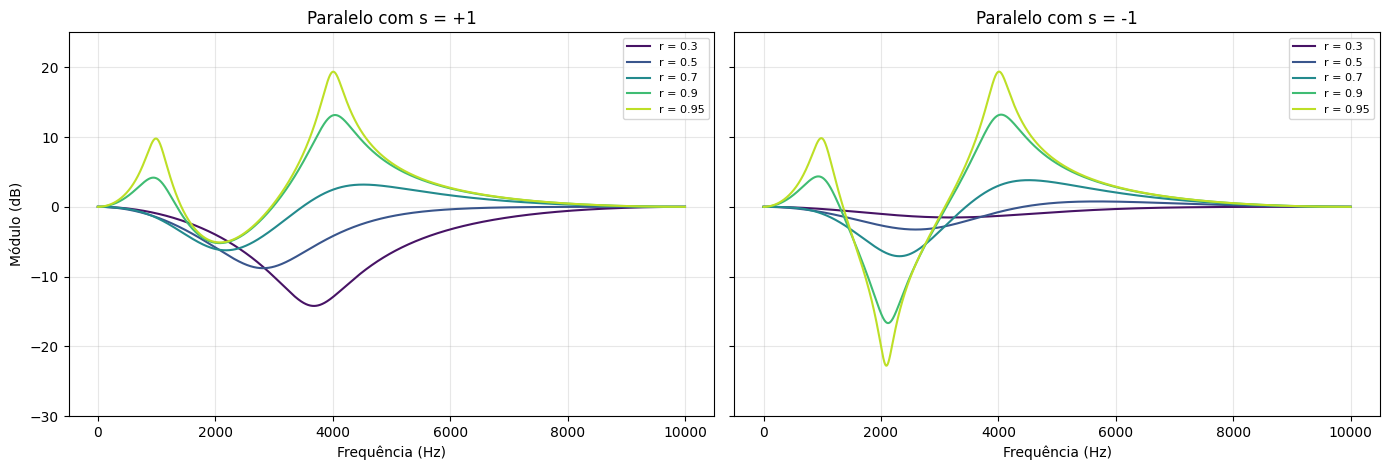

In [ ]:
# Varredura de r (s = +1 e s = -1)
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
cores = plt.cm.viridis(np.linspace(0.05, 0.9, 5))
for ax, s in zip(eixos, (+1, -1)):
    for r, cor in zip([0.3, 0.5, 0.7, 0.9, 0.95], cores):
        bl, al = projetar_bloco("lpf", 1000, r, FS); bh, ah = projetar_bloco("hpf", 4000, r, FS)
        b = np.convolve(bl, ah) + s * np.convolve(bh, al); a = np.convolve(al, ah)
        ax.plot(F_PLOT, em_db(resposta(b, a, F_PLOT, FS)), color=cor, label=f"r = {r}")
    ax.set_title(f"Paralelo com s = {s:+d}"); ax.set_xlabel("Frequência (Hz)"); ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    ax.set_ylim(-30, 25)
eixos[0].set_ylabel("Módulo (dB)")
plt.tight_layout(); plt.show()

### Comparação com o notch da Questão 1(d)

filtro                                 ordem  mín (dB)   f_mín  pico (dB)   banda com atenuação >= 3 dB
Rejeita-faixas (paralelo, r = 0,5)         4      -8.8    2812       0.00    1417 a  4323 Hz
Notch 3000 Hz (Q1d), r = 0.9               2    -299.6    3000       0.09    2671 a  3328 Hz
Notch 3000 Hz (Q1d), r = 0.5               2    -298.6    3000       2.85    1700 a  4216 Hz


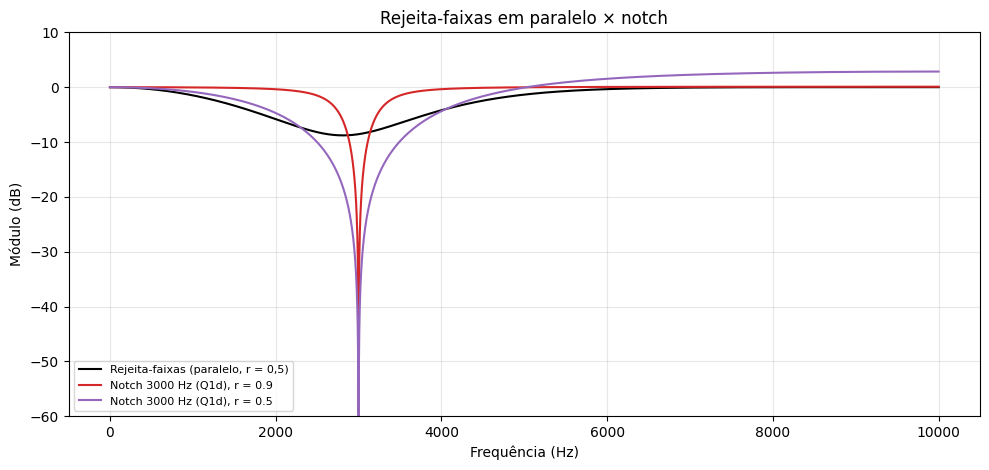

In [ ]:
comp3 = {"Rejeita-faixas (paralelo, r = 0,5)": (b_q3, a_q3)}
for r in (0.9, 0.5):
    comp3[f"Notch 3000 Hz (Q1d), r = {r}"] = projetar_bloco("notch", 3000, r, FS)

print(f"{'filtro':<38} {'ordem':>5} {'mín (dB)':>9} {'f_mín':>7} {'pico (dB)':>10}   banda com atenuação >= 3 dB")
fig, ax = plt.subplots(figsize=(10, 4.8))
for (nome, (b, a)), cor in zip(comp3.items(), ["k", "tab:red", "tab:purple"]):
    H = resposta(b, a, F_PLOT, FS)
    ax.plot(F_PLOT, em_db(H), color=cor, label=nome)
    m = medidas_rejeitafaixas(b, a)
    print(f"{nome:<38} {max(len(a), len(b))-1:5d} {m['minimo']:9.1f} {m['f_min']:7.0f} {m['pico']:10.2f}   {m['f3'][0]:5.0f} a {m['f3'][1]:5.0f} Hz")
ax.set_ylim(-60, 10); ax.set_xlabel("Frequência (Hz)"); ax.set_ylabel("Módulo (dB)")
ax.set_title("Rejeita-faixas em paralelo × notch"); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## Questão 4 — Quantização dos coeficientes (filtros das Questões 2 e 3)

**Quantizador.** Ponto fixo com sinal e $b$ bits, aplicado a cada vetor de coeficientes: o passo é
$\Delta = 2^{\,e-(b-1)}$, com $e=\lfloor\log_2\max|v|\rfloor+1$ (a escala é escolhida pelo maior coeficiente do vetor), e
$v_q=\Delta\cdot\operatorname{clip}\big(\operatorname{round}(v/\Delta),\,-2^{b-1},\,2^{b-1}-1\big)$.
O coeficiente $a_0=1$ do denominador não é quantizado. Em cada vetor, o numerador e o denominador têm escalas próprias.

**Duas estruturas.** (1) *Forma direta*: quantizam-se os coeficientes do filtro resultante, $B(z)/A(z)$ de 4ª ordem;
(2) *blocos*: quantiza-se cada bloco de 2ª ordem separadamente e recompõe-se o filtro (cascata: produto das respostas;
paralelo: soma). Métricas: raio máximo dos polos (estabilidade exige $<1$), erro relativo máximo da resposta,
$20\log_{10}(\max|H_q-H|/\max|H|)$, e deslocamento máximo dos polos em relação aos originais.


In [ ]:
def quantizar(v, bits):
    v = np.asarray(v, float)
    vmax = np.max(np.abs(v))
    if vmax == 0:
        return v.copy()
    e = np.floor(np.log2(vmax)) + 1                    # alcance [-2^e, 2^e)
    passo = 2.0 ** (e - (bits - 1))
    return np.clip(np.round(v / passo), -2 ** (bits - 1), 2 ** (bits - 1) - 1) * passo


def quantizar_ba(b, a, bits):
    return quantizar(b, bits), np.r_[1.0, quantizar(a[1:], bits)]


def quantizar_blocos(blocos, bits):
    return [quantizar_ba(b, a, bits) for b, a in blocos]


def total_estrutura(estrutura, blocos):
    return combinar_cascata(blocos) if estrutura == "cascata" else combinar_paralelo(blocos)


def resposta_estrutura(estrutura, blocos, f, fs):
    Hs = [resposta(b, a, f, fs) for b, a in blocos]
    return np.prod(Hs, axis=0) if estrutura == "cascata" else np.sum(Hs, axis=0)


def desloc_max(ref, q):
    if len(ref) == 0:
        return 0.0
    if len(q) == 0:
        return np.nan
    return max(np.min(np.abs(q - r0)) for r0 in ref)


def avaliar_quantizacao(estrutura, blocos, bits_lista, f, fs):
    b_ref, a_ref = total_estrutura(estrutura, blocos)
    H_ref = resposta_estrutura(estrutura, blocos, f, fs)
    z_ref, p_ref = zeros_polos(b_ref, a_ref)
    pico = np.max(np.abs(H_ref))

    def registro(H, b, a, coef):
        z, p = zeros_polos(b, a)
        p_max = np.max(np.abs(p)) if len(p) else 0.0
        estado = "estável" if p_max < 1 - 1e-6 else ("marginal" if p_max <= 1 + 1e-6 else "instável")
        return dict(H=H, polos=p, zeros=z, p_max=p_max, estado=estado, estavel=(estado == "estável"), coef=coef,
                    erro_dB=20 * np.log10(np.max(np.abs(H - H_ref)) / pico + 1e-15),
                    desl_polos=desloc_max(p_ref, p), desl_zeros=desloc_max(z_ref, z))

    res = {}
    for bits in bits_lista:
        bq, aq = quantizar_ba(b_ref, a_ref, bits)                               # (1) forma direta
        bl_q = quantizar_blocos(blocos, bits)                                   # (2) bloco a bloco
        bb, ab = total_estrutura(estrutura, bl_q)
        res[bits] = dict(direta=registro(resposta(bq, aq, f, fs), bq, aq, (bq, aq)),
                         blocos=registro(resposta_estrutura(estrutura, bl_q, f, fs), bb, ab, bl_q))
    return dict(ref=dict(H=H_ref, zeros=z_ref, polos=p_ref), bits=res)


def imprimir_tabela_quant(res, bits_lista):
    rot = {"estável": "sim", "marginal": "marg.", "instável": "NÃO"}
    fe = lambda v: "indef." if not np.isfinite(v) else f"{v:.1f}"
    print(f"{'bits':>4} | {'DIRETA |p|max':>13} {'estável':>8} {'erro (dB)':>10} {'desl.polos':>11} {'desl.zeros':>11} | "
          f"{'BLOCOS |p|max':>13} {'estável':>8} {'erro (dB)':>10} {'desl.polos':>11} {'desl.zeros':>11}")
    for bits in bits_lista:
        d, k = res["bits"][bits]["direta"], res["bits"][bits]["blocos"]
        print(f"{bits:4d} | {d['p_max']:13.4f} {rot[d['estado']]:>8} {fe(d['erro_dB']):>10} {d['desl_polos']:11.4f} {d['desl_zeros']:11.4f} | "
              f"{k['p_max']:13.4f} {rot[k['estado']]:>8} {fe(k['erro_dB']):>10} {k['desl_polos']:11.4f} {k['desl_zeros']:11.4f}")


def plotar_quant_resposta(res, bits_lista, f, titulo, ylim=(-80, 25), log_x=False):
    fig, eixos = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
    cores = plt.cm.plasma(np.linspace(0.05, 0.85, len(bits_lista)))
    for ax, chave, nome in zip(eixos, ["direta", "blocos"], ["Quantização do filtro resultante (forma direta)", "Quantização bloco a bloco"]):
        ax.plot(f, em_db(res["ref"]["H"]), "k", lw=2.4, label="original")
        for bits, cor in zip(bits_lista, cores):
            r = res["bits"][bits][chave]
            ax.plot(f, em_db(r["H"]), color=cor, lw=1.0, label=f"{bits} bits" + ("" if r["estavel"] else f" ({r['estado']})"))
        ax.set_title(f"{titulo} — {nome}", fontsize=10); ax.set_xlabel("Frequência (Hz)"); ax.set_ylim(*ylim)
        if log_x:
            ax.set_xscale("log"); ax.set_xlim(20, f[-1])
        ax.grid(True, alpha=0.3); ax.legend(fontsize=7, ncol=2)
    eixos[0].set_ylabel("Módulo (dB)")
    plt.tight_layout(); plt.show()


def plotar_quant_pz(res, bits_lista, titulo, lim=1.6):
    fig, eixos = plt.subplots(2, len(bits_lista), figsize=(3.3 * len(bits_lista), 7), squeeze=False)
    theta = np.linspace(0, 2 * np.pi, 400)
    for j, bits in enumerate(bits_lista):
        for i, chave in enumerate(["direta", "blocos"]):
            ax = eixos[i, j]; d = res["bits"][bits][chave]
            ax.plot(np.cos(theta), np.sin(theta), "k--", lw=0.6)
            ax.plot(res["ref"]["zeros"].real, res["ref"]["zeros"].imag, "o", mfc="none", mec="0.6", ms=12)
            ax.plot(res["ref"]["polos"].real, res["ref"]["polos"].imag, "x", color="0.6", ms=12)
            ax.plot(d["zeros"].real, d["zeros"].imag, "o", mfc="none", mec="tab:blue", ms=6)
            ax.plot(d["polos"].real, d["polos"].imag, "x", color="tab:red", ms=6)
            ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.grid(True, alpha=0.3)
            ax.set_title(f"{bits} bits — {'direta' if chave == 'direta' else 'blocos'}" + ("" if d["estavel"] else f" ({d['estado']})"), fontsize=9)
    fig.suptitle(f"{titulo}: original (cinza) × quantizado (zeros ○ azuis, polos × vermelhos)")
    plt.tight_layout(); plt.show()


BITS_Q4 = [2, 4, 8, 16, 32]

### Filtro da Questão 2 (cascata, projeto direto)

bits | DIRETA |p|max  estável  erro (dB)  desl.polos  desl.zeros | BLOCOS |p|max  estável  erro (dB)  desl.polos  desl.zeros
   2 |        1.0000    marg.       66.3      0.5136      0.5176 |        0.7071      sim        1.7      0.3836      1.0000
   4 |        0.7874      sim      -12.1      0.2049      0.2929 |        0.6124      sim       -5.3      0.0897      0.5000
   8 |        0.6078      sim      -38.7      0.0227      0.0000 |        0.5995      sim      -28.7      0.0012      0.1514
  16 |        0.6000      sim      -77.0      0.0001      0.0051 |        0.6000      sim      -88.9      0.0000      0.0079
  32 |        0.6000      sim     -176.2      0.0000      0.0000 |        0.6000      sim     -184.0      0.0000      0.0000

Coeficientes do filtro resultante: |a_i| entre 0.1296 e 1.3416 | |b_i| entre 0.0000 e 0.2882


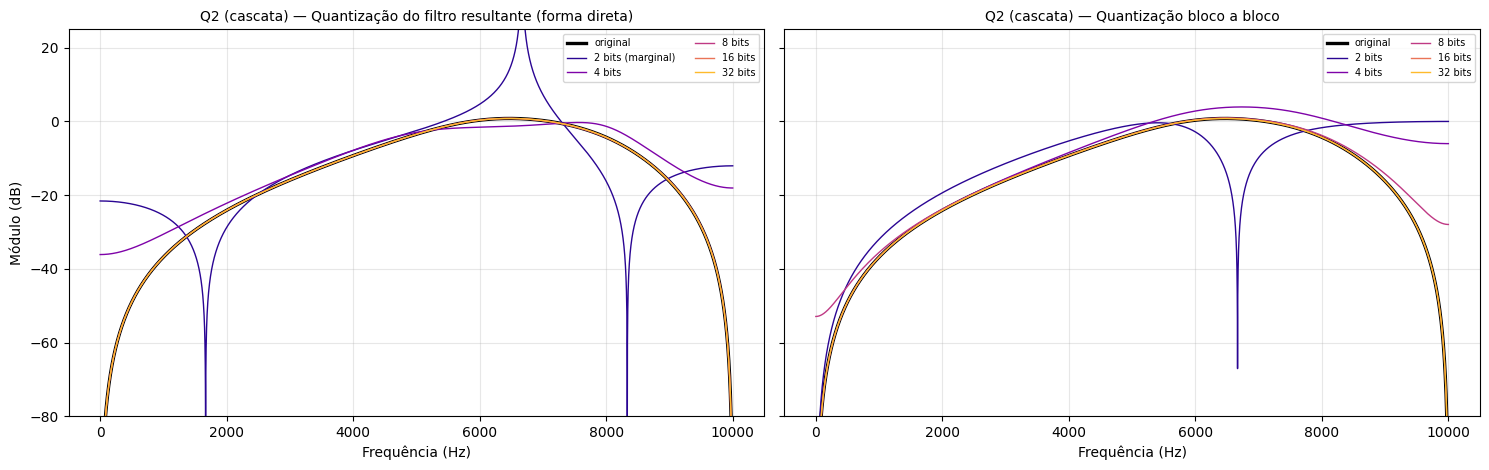

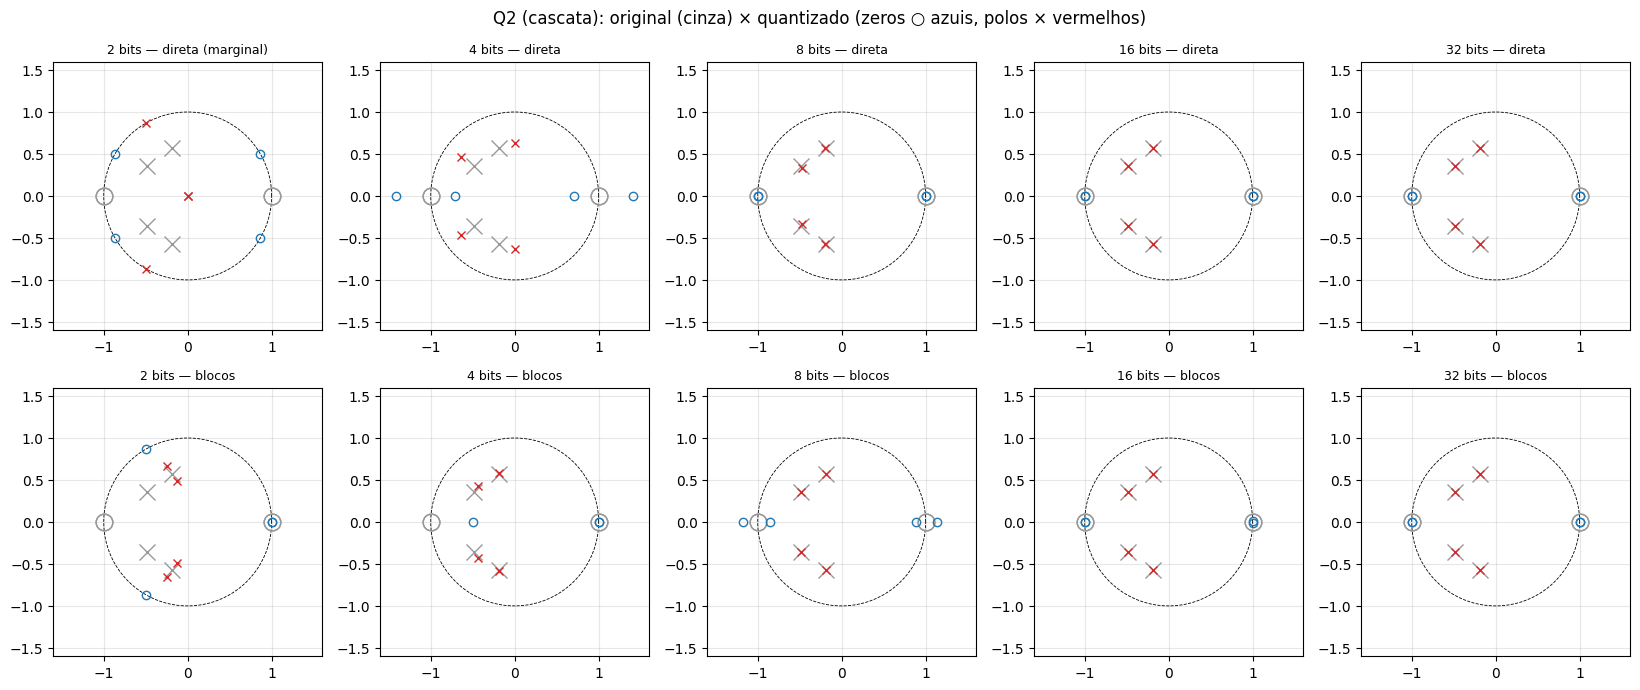

In [ ]:
res_q2 = avaliar_quantizacao("cascata", blocos_q2, BITS_Q4, F_PLOT, FS)
imprimir_tabela_quant(res_q2, BITS_Q4)
b_ref, a_ref = total_estrutura("cascata", blocos_q2)
print("\nCoeficientes do filtro resultante: |a_i| entre", f"{np.min(np.abs(a_ref[1:])):.4f} e {np.max(np.abs(a_ref[1:])):.4f}",
      "| |b_i| entre", f"{np.min(np.abs(b_ref)):.4f} e {np.max(np.abs(b_ref)):.4f}")
plotar_quant_resposta(res_q2, BITS_Q4, F_PLOT, "Q2 (cascata)")
plotar_quant_pz(res_q2, BITS_Q4, "Q2 (cascata)")

### Filtro da Questão 3 (paralelo)

In [ ]:
res_q3 = avaliar_quantizacao("paralelo", blocos_q3, BITS_Q4, F_PLOT, FS)
imprimir_tabela_quant(res_q3, BITS_Q4)
b_ref3, a_ref3 = total_estrutura("paralelo", blocos_q3)
print("\nCoeficientes do filtro resultante: |a_i| entre", f"{np.min(np.abs(a_ref3[1:])):.4f} e {np.max(np.abs(a_ref3[1:])):.4f}",
      "| |b_i| entre", f"{np.min(np.abs(b_ref3)):.4f} e {np.max(np.abs(b_ref3)):.4f}")
plotar_quant_resposta(res_q3, BITS_Q4, F_PLOT, "Q3 (paralelo)")
plotar_quant_pz(res_q3, BITS_Q4, "Q3 (paralelo)")

bits | DIRETA |p|max  estável  erro (dB)  desl.polos  desl.zeros | BLOCOS |p|max  estável  erro (dB)  desl.polos  desl.zeros
   2 |        1.0000    marg.        6.0      0.5000      0.3865 |        1.0000    marg.     indef.      0.4812      0.2694
   4 |        0.6880      sim       -9.4      0.2627      0.3865 |        0.5000      sim      -18.1      0.1564      0.0273
   8 |        0.5063      sim      -35.0      0.0140      0.0184 |        0.5000      sim      -43.6      0.0034      0.0015
  16 |        0.5000      sim      -79.1      0.0001      0.0001 |        0.5000      sim      -89.8      0.0000      0.0000
  32 |        0.5000      sim     -181.5      0.0000      0.0000 |        0.5000      sim     -185.1      0.0000      0.0000

Coeficientes do filtro resultante: |a_i| entre 0.0625 e 1.2601 | |b_i| entre 0.1161 e 1.2758


### Sensibilidade numérica: deslocamento dos polos × número de bits, para diferentes raios $r$

    r bits |  desl. polos (blocos)  estado |  desl. polos (direta)  estado
 0.60    4 |               0.08968    est. |               0.20491    est.
 0.60    6 |               0.02203    est. |               0.06906    est.
 0.60    8 |               0.00117    est. |               0.02274    est.
 0.60   10 |               0.00081    est. |               0.00733    est.
 0.60   12 |               0.00013    est. |               0.00071    est.
 0.60   14 |               0.00002    est. |               0.00043    est.
 0.60   16 |               0.00002    est. |               0.00009    est.
 0.60   20 |               0.00000    est. |               0.00000    est.
 0.60   24 |               0.00000    est. |               0.00000    est.
 0.60   32 |               0.00000    est. |               0.00000    est.
 0.90    4 |               0.09846    est. |               0.22995   marg.
 0.90    6 |               0.01765    est. |               0.06417    est.
 0.90    8 |             

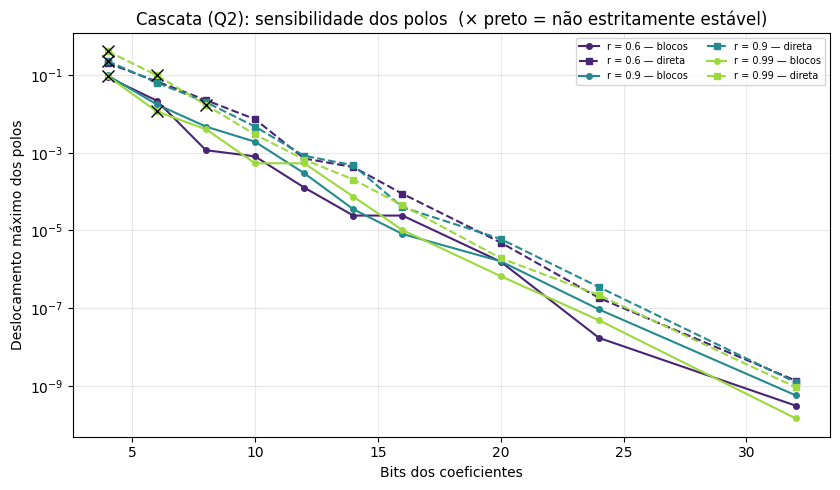

    r bits |  desl. polos (blocos)  estado |  desl. polos (direta)  estado
 0.50    4 |               0.15643    est. |               0.26275    est.
 0.50    6 |               0.02063    est. |               0.06316    est.
 0.50    8 |               0.00338    est. |               0.01397    est.
 0.50   10 |               0.00022    est. |               0.01138    est.
 0.50   12 |               0.00019    est. |               0.00166    est.
 0.50   14 |               0.00001    est. |               0.00059    est.
 0.50   16 |               0.00001    est. |               0.00006    est.
 0.50   20 |               0.00000    est. |               0.00000    est.
 0.50   24 |               0.00000    est. |               0.00000    est.
 0.50   32 |               0.00000    est. |               0.00000    est.
 0.90    4 |               0.29761   marg. |               0.56492   INST.
 0.90    6 |               0.04090    est. |               0.06027    est.
 0.90    8 |             

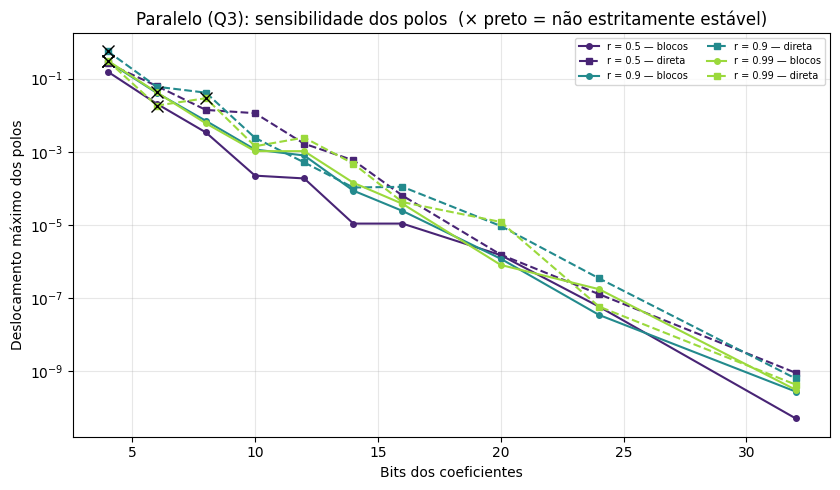

In [ ]:
BITS_SENS = [4, 6, 8, 10, 12, 14, 16, 20, 24, 32]

def curva_sensibilidade(construir, estrutura, valores_r):
    saida = {}
    for r in valores_r:
        res = avaliar_quantizacao(estrutura, construir(r), BITS_SENS, F_PLOT, FS)
        saida[r] = {k: [(res["bits"][b][k]["desl_polos"], res["bits"][b][k]["estavel"], res["bits"][b][k]["estado"]) for b in BITS_SENS] for k in ("direta", "blocos")}
    return saida


def plotar_sensibilidade(curvas, titulo):
    ab = {"estável": "est.", "marginal": "marg.", "instável": "INST."}
    print(f"{'r':>5} {'bits':>4} | {'desl. polos (blocos)':>21} {'estado':>7} | {'desl. polos (direta)':>21} {'estado':>7}")
    for r, d in curvas.items():
        for i, bits in enumerate(BITS_SENS):
            print(f"{r:5.2f} {bits:4d} | {d['blocos'][i][0]:21.5f} {ab[d['blocos'][i][2]]:>7} | {d['direta'][i][0]:21.5f} {ab[d['direta'][i][2]]:>7}")
    fig, ax = plt.subplots(figsize=(8.5, 5))
    cores = plt.cm.viridis(np.linspace(0.1, 0.85, len(curvas)))
    for (r, d), cor in zip(curvas.items(), cores):
        for chave, estilo, marc in (("blocos", "-", "o"), ("direta", "--", "s")):
            y = np.array([v[0] for v in d[chave]]); est = np.array([v[1] for v in d[chave]], dtype=bool)
            ax.semilogy(BITS_SENS, np.maximum(y, 1e-12), estilo, marker=marc, color=cor, ms=4,
                        label=f"r = {r} — {'blocos' if chave == 'blocos' else 'direta'}")
            ax.semilogy(np.array(BITS_SENS)[~est], np.maximum(y, 1e-12)[~est], "x", color="k", ms=9)
    ax.set_xlabel("Bits dos coeficientes"); ax.set_ylabel("Deslocamento máximo dos polos")
    ax.set_title(titulo + "  (× preto = não estritamente estável)"); ax.grid(True, which="both", alpha=0.3); ax.legend(fontsize=7, ncol=2)
    plt.tight_layout(); plt.show()


curvas_q2 = curva_sensibilidade(lambda r: cascata_q2(6000, 8000, r, r), "cascata", [0.6, 0.9, 0.99])
plotar_sensibilidade(curvas_q2, "Cascata (Q2): sensibilidade dos polos")
curvas_q3 = curva_sensibilidade(lambda r: paralelo_q3(r, r), "paralelo", [0.5, 0.9, 0.99])
plotar_sensibilidade(curvas_q3, "Paralelo (Q3): sensibilidade dos polos")

## Questão 5 — Remoção de interferências em `handel.wav`

$y(t)=x(t)+0{,}05\cos(200\pi t)+0{,}075\sin(4000\pi t)+n(t)$, com $n(t)$ ruído branco gaussiano de variância
$\sigma^2\in\{10^{-2},10^{-1},1\}$. As interferências são **tons em 100 Hz** ($0{,}05\cos(2\pi\cdot100\,t)$)
e **2000 Hz** ($0{,}075\sin(2\pi\cdot2000\,t)$). O ruído é gerado a partir de um vetor-base $N(0,1)$ fixo (semente 0),
multiplicado por $\sqrt{\sigma^2}$, de modo que apenas a variância muda entre os casos.


### (a) Sinal contaminado: tempo e frequência

In [ ]:
fs_a, x = ler_wav("handel.wav")
N = len(x); t = np.arange(N) / fs_a
F0_BAIXA, F0_ALTA = 100.0, 2000.0

interf_baixa = 0.05 * np.cos(200 * np.pi * t)
interf_alta = 0.075 * np.sin(4000 * np.pi * t)
interf = interf_baixa + interf_alta
SIGMA2 = [1e-2, 1e-1, 1.0]
z_base = np.random.default_rng(0).standard_normal(N)
y_ruidoso = {s2: x + interf + np.sqrt(s2) * z_base for s2 in SIGMA2}

P = lambda v: np.mean(v ** 2)
snr = lambda ref, est: 10 * np.log10(P(ref) / P(est - ref))

print(f"handel.wav: fs = {fs_a} Hz, N = {N} amostras, duração = {N/fs_a:.2f} s, pico = {np.max(np.abs(x)):.3f}")
print(f"Potências: x = {P(x):.5f} | tom de 100 Hz = {P(interf_baixa):.5f} | tom de 2000 Hz = {P(interf_alta):.5f} "
      f"| soma dos tons = {P(interf):.5f}")
for s2 in SIGMA2:
    print(f"σ² = {s2:<5}: potência do ruído = {s2:.3f} | SNR de entrada = {snr(x, y_ruidoso[s2]):6.2f} dB")

handel.wav: fs = 8192 Hz, N = 73113 amostras, duração = 8.92 s, pico = 0.800
Potências: x = 0.03851 | tom de 100 Hz = 0.00125 | tom de 2000 Hz = 0.00281 | soma dos tons = 0.00406
σ² = 0.01 : potência do ruído = 0.010 | SNR de entrada =   4.35 dB
σ² = 0.1  : potência do ruído = 0.100 | SNR de entrada =  -4.33 dB
σ² = 1.0  : potência do ruído = 1.000 | SNR de entrada = -14.17 dB


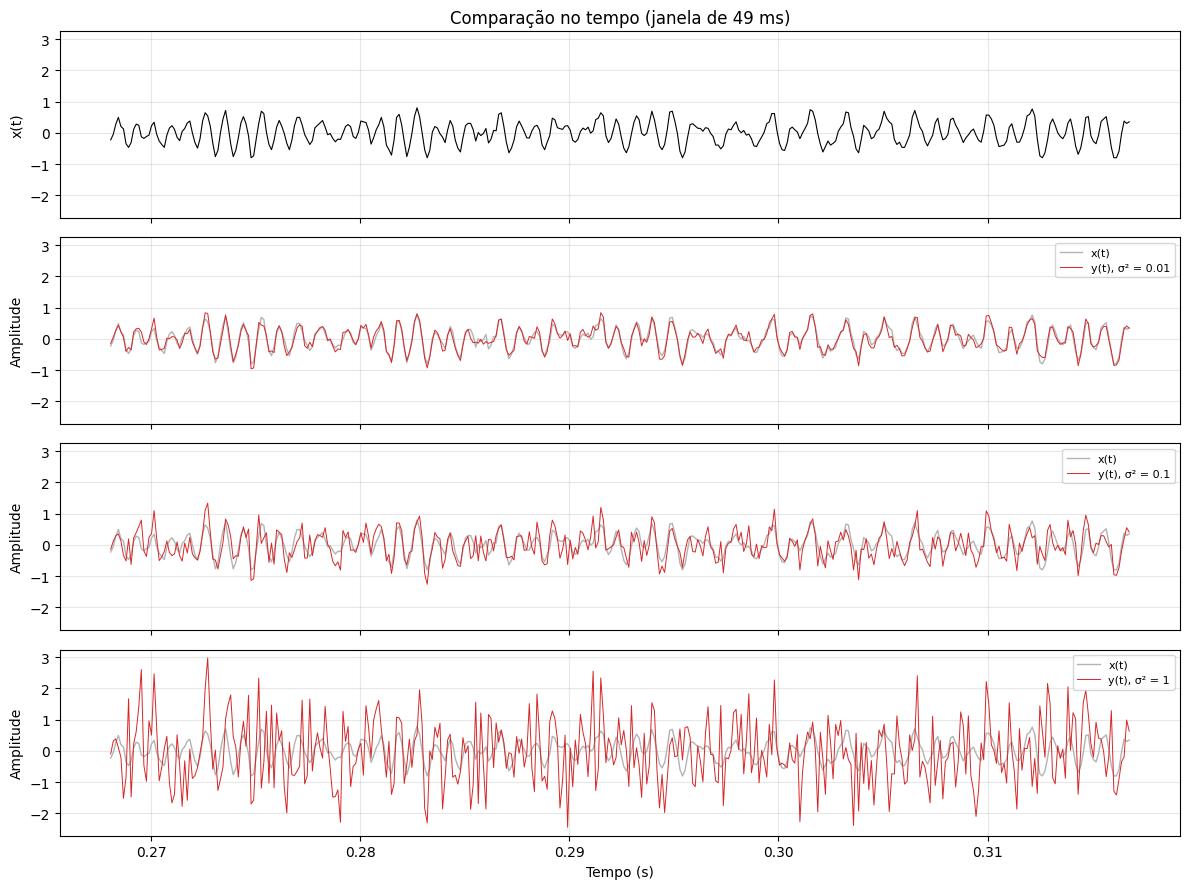

In [ ]:
energia_local = np.convolve(x ** 2, np.ones(400) / 400, mode="same")
i0 = int(np.argmax(energia_local)); janela = slice(i0 - 200, i0 + 200)

fig, eixos = plt.subplots(4, 1, figsize=(12, 9), sharex=True, sharey=True)
eixos[0].plot(t[janela], x[janela], color="k", lw=0.8); eixos[0].set_ylabel("x(t)")
eixos[0].set_title(f"Comparação no tempo (janela de {400/fs_a*1000:.0f} ms)")
for ax, s2 in zip(eixos[1:], SIGMA2):
    ax.plot(t[janela], x[janela], color="0.7", lw=1.0, label="x(t)")
    ax.plot(t[janela], y_ruidoso[s2][janela], color="tab:red", lw=0.7, label=f"y(t), σ² = {s2:g}")
    ax.set_ylabel("Amplitude"); ax.legend(fontsize=8, loc="upper right")
eixos[-1].set_xlabel("Tempo (s)")
for ax in eixos:
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

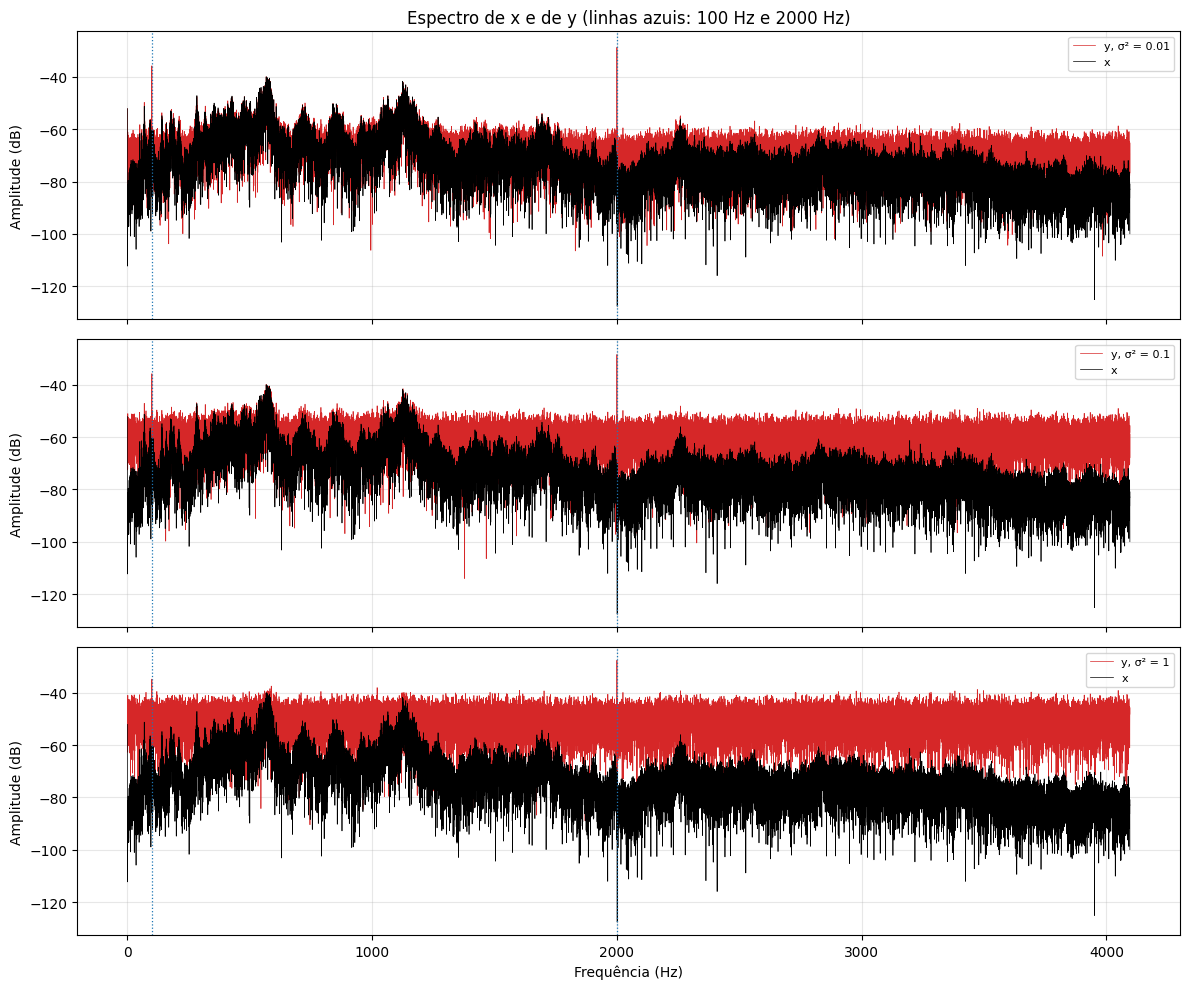

Sinal original:


Sinal contaminado, σ² = 0.01:


Sinal contaminado, σ² = 0.1:


Sinal contaminado, σ² = 1:


In [ ]:
f_x, a_x = calculate_spectrum(x, fs_a)
fig, eixos = plt.subplots(3, 1, figsize=(12, 10), sharex=True, sharey=True)
for ax, s2 in zip(eixos, SIGMA2):
    f_y, a_y = calculate_spectrum(y_ruidoso[s2], fs_a)
    ax.plot(f_y, 20 * np.log10(a_y + 1e-12), color="tab:red", lw=0.5, label=f"y, σ² = {s2:g}")
    ax.plot(f_x, 20 * np.log10(a_x + 1e-12), color="k", lw=0.5, label="x")
    for f0 in (F0_BAIXA, F0_ALTA):
        ax.axvline(f0, color="tab:blue", ls=":", lw=0.9)
    ax.set_ylabel("Amplitude (dB)"); ax.legend(fontsize=8, loc="upper right"); ax.grid(True, alpha=0.3)
eixos[0].set_title("Espectro de x e de y (linhas azuis: 100 Hz e 2000 Hz)")
eixos[-1].set_xlabel("Frequência (Hz)")
plt.tight_layout(); plt.show()

print("Sinal original:"); tocar(x, fs_a)
for s2 in SIGMA2:
    print(f"Sinal contaminado, σ² = {s2:g}:"); tocar(y_ruidoso[s2], fs_a)

### (b) Análise espectral: que filtro serve para cada componente?

In [ ]:
# Detectabilidade dos tons: amplitude espectral do pico x piso de ruído vizinho
def amplitude_pico(f, a, f0, tol=3.0):
    return a[np.abs(f - f0) <= tol].max()

def piso_vizinho(f, a, f0, largura=100.0, guarda=10.0):
    sel = (np.abs(f - f0) <= largura) & (np.abs(f - f0) > guarda)
    return np.median(a[sel])

print(f"Amplitude espectral esperada dos tons: 100 Hz -> {0.05/2:.4f}; 2000 Hz -> {0.075/2:.4f}")
print(f"Maior componente de x a ±3 Hz de 100 Hz: {amplitude_pico(f_x, a_x, F0_BAIXA):.4f} | de 2000 Hz: {amplitude_pico(f_x, a_x, F0_ALTA):.4f}")
print(f"{'σ²':>6} | {'pico 100 Hz':>11} {'piso (dB acima)':>16} | {'pico 2000 Hz':>12} {'piso (dB acima)':>16}")
for s2 in SIGMA2:
    f_y, a_y = calculate_spectrum(y_ruidoso[s2], fs_a)
    linha = []
    for f0 in (F0_BAIXA, F0_ALTA):
        pico, piso = amplitude_pico(f_y, a_y, f0), piso_vizinho(f_y, a_y, f0)
        linha += [pico, 20 * np.log10(pico / piso)]
    print(f"{s2:6g} | {linha[0]:11.4f} {linha[1]:16.1f} | {linha[2]:12.4f} {linha[3]:16.1f}")

Amplitude espectral esperada dos tons: 100 Hz -> 0.0250; 2000 Hz -> 0.0375
Maior componente de x a ±3 Hz de 100 Hz: 0.0010 | de 2000 Hz: 0.0003
    σ² | pico 100 Hz  piso (dB acima) | pico 2000 Hz  piso (dB acima)
  0.01 |      0.0163             32.3 |       0.0367             40.8
   0.1 |      0.0163             24.0 |       0.0379             31.5
     1 |      0.0182             15.2 |       0.0416             22.4


Energia acumulada de x até:
     100 Hz:   0.58%
     200 Hz:   1.74%
     500 Hz:  16.98%
    1000 Hz:  64.25%
    2000 Hz:  95.94%
    2500 Hz:  97.42%
    3000 Hz:  98.77%
    3500 Hz:  99.67%
    4000 Hz:  99.97%

Ganho de SNR máximo por redução de banda do ruído branco (LPF ideal, sem perda de sinal):
   corte em 2000 Hz: 3.11 dB
   corte em 2500 Hz: 2.14 dB
   corte em 3000 Hz: 1.35 dB
   corte em 3500 Hz: 0.68 dB


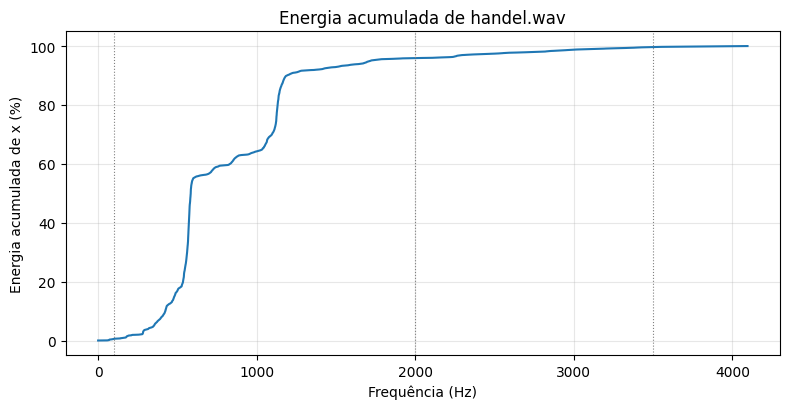

In [ ]:
# Distribuição de energia de x em frequência: define onde há sinal útil
energia_acum = np.cumsum(a_x ** 2) / np.sum(a_x ** 2)
print("Energia acumulada de x até:")
for fx in (100, 200, 500, 1000, 2000, 2500, 3000, 3500, 4000):
    print(f"   {fx:5d} Hz: {100*energia_acum[np.searchsorted(f_x, fx)]:6.2f}%")
print("\nGanho de SNR máximo por redução de banda do ruído branco (LPF ideal, sem perda de sinal):")
for fc in (2000, 2500, 3000, 3500):
    print(f"   corte em {fc} Hz: {10*np.log10((fs_a/2)/fc):.2f} dB")

plt.figure(figsize=(8, 4.2))
plt.plot(f_x, 100 * energia_acum)
for fx in (100, 2000, 3500):
    plt.axvline(fx, color="gray", ls=":", lw=0.8)
plt.xlabel("Frequência (Hz)"); plt.ylabel("Energia acumulada de x (%)")
plt.title("Energia acumulada de handel.wav"); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

**Leitura da análise.**
- **Tom de 100 Hz** (banda estreita, abaixo de quase toda a energia útil): removível por **notch**; um **passa-altas** também serve, mas cortaria parte do conteúdo grave.
- **Tom de 2000 Hz** (banda estreita, mas **dentro da banda útil**, onde se concentra a maior parte da energia): apenas um **notch** o remove sem sacrificar o sinal; passa-baixas, passa-altas ou passa-faixas removeriam muito conteúdo.
- **Ruído branco**: ocupa toda a banda $[0, f_s/2]$. Só a parcela **fora** da banda do sinal (acima de ≈3,5 kHz) pode ser reduzida por um **passa-baixas**; a parcela **dentro** da banda do sinal não é separável por filtragem linear invariante no tempo, o que limita o ganho de SNR.


### (c) Projeto da cascata de blocos de 2ª ordem

In [ ]:
# Justificativa de r nos notches: largura de banda x distorção do sinal (σ² = 0,1)
def metricas_filtragem(sos, x_ref, y, e):
    xh, xf, ef = sosfilt(sos, y), sosfilt(sos, x_ref), sosfilt(sos, e)
    return dict(snr_in=snr(x_ref, y), snr_out=snr(x_ref, xh), mse_in=P(y - x_ref), mse_out=P(xh - x_ref),
                p_res=P(ef), p_dist=P(xf - x_ref), xh=xh)

sos_de = lambda blocos: np.array([np.r_[b, a] for b, a in blocos])
y01 = y_ruidoso[0.1]; e01 = y01 - x

print("Notch de 100 Hz (isolado):")
print(f"{'r':>6} {'B(-3dB) Hz':>11} {'const. tempo (ms)':>18} {'dist (% de Px)':>15} {'SNR out (dB)':>13}")
for r in (0.95, 0.98, 0.99, 0.995, 0.998):
    m = metricas_filtragem(sos_de([projetar_bloco("notch", 100, r, fs_a)]), x, y01, e01)
    print(f"{r:6.3f} {(1-r)*fs_a/np.pi:11.1f} {1000/((1-r)*fs_a):18.1f} {100*m['p_dist']/P(x):15.4f} {m['snr_out']:13.3f}")
print("\nNotch de 2000 Hz (isolado):")
for r in (0.9, 0.95, 0.98, 0.99, 0.995):
    m = metricas_filtragem(sos_de([projetar_bloco("notch", 2000, r, fs_a)]), x, y01, e01)
    print(f"{r:6.3f} {(1-r)*fs_a/np.pi:11.1f} {1000/((1-r)*fs_a):18.1f} {100*m['p_dist']/P(x):15.4f} {m['snr_out']:13.3f}")

R_N100, R_N2K = 0.995, 0.98
base = [projetar_bloco("notch", F0_BAIXA, R_N100, fs_a), projetar_bloco("notch", F0_ALTA, R_N2K, fs_a)]
print("\nPassa-baixas (após os dois notches): frequência do polo x r")
print(f"{'fc':>6} {'r':>5} {'f(-3dB) Hz':>11} {'pico (dB)':>10} {'dist (% de Px)':>15} {'SNR out (dB)':>13}")
Fa = np.linspace(0, fs_a / 2, 8192)
for fc in (2500, 3000, 3500, 3800):
    for r in (0.4, 0.6, 0.8):
        bq_, aq_ = projetar_bloco("lpf", fc, r, fs_a); m_ = np.abs(resposta(bq_, aq_, Fa, fs_a))
        f3 = Fa[np.where(m_ >= 1 / np.sqrt(2))[0][-1]]
        m = metricas_filtragem(sos_de(base + [(bq_, aq_)]), x, y01, e01)
        print(f"{fc:6d} {r:5.1f} {f3:11.0f} {20*np.log10(m_.max()):10.2f} {100*m['p_dist']/P(x):15.2f} {m['snr_out']:13.3f}")
print(f"\nSNR de entrada (σ² = 0,1): {snr(x, y01):.3f} dB")

Notch de 100 Hz (isolado):
     r  B(-3dB) Hz  const. tempo (ms)  dist (% de Px)  SNR out (dB)
 0.950       130.4                2.4         26.3591        -7.489
 0.980        52.2                6.1          1.8616        -4.803
 0.990        26.1               12.2          0.5392        -4.393
 0.995        13.0               24.4          0.2196        -4.298
 0.998         5.2               61.0          0.0713        -4.277

Notch de 2000 Hz (isolado):
 0.900       260.8                1.2          1.7260        -3.813
 0.950       130.4                2.4          0.5722        -4.000
 0.980        52.2                6.1          0.1628        -4.118
 0.990        26.1               12.2          0.0764        -4.159
 0.995        13.0               24.4          0.0364        -4.179

Passa-baixas (após os dois notches): frequência do polo x r
    fc     r  f(-3dB) Hz  pico (dB)  dist (% de Px)  SNR out (dB)
  2500   0.4        2286       0.00           21.46        -2.038
  2

Notch 100 Hz:
   H(z) = [(0.999252) z^-0 + (-1.992628) z^-1 + (0.999252) z^-2] / [(1.000000) z^-0 + (-1.984150) z^-1 + (0.990025) z^-2]
   polos: raio = 0.9950, ângulo = 4.39 graus (f = 100.0 Hz); zeros: raio = [1. 1.]
Notch 2000 Hz:
   H(z) = [(0.980208) z^-0 + (-0.072157) z^-1 + (0.980208) z^-2] / [(1.000000) z^-0 + (-0.072142) z^-1 + (0.960400) z^-2]
   polos: raio = 0.9800, ângulo = 87.89 graus (f = 2000.0 Hz); zeros: raio = [1. 1.]
Passa-baixas 3500 Hz:
   H(z) = [(0.609197) z^-0 + (1.218395) z^-1 + (0.609197) z^-2] / [(1.000000) z^-0 + (1.076789) z^-1 + (0.360000) z^-2]
   polos: raio = 0.6000, ângulo = 153.81 graus (f = 3500.0 Hz); zeros: raio = [1. 1.]

Filtro completo: ordem 6, |polo|max = 0.9950 (estável)


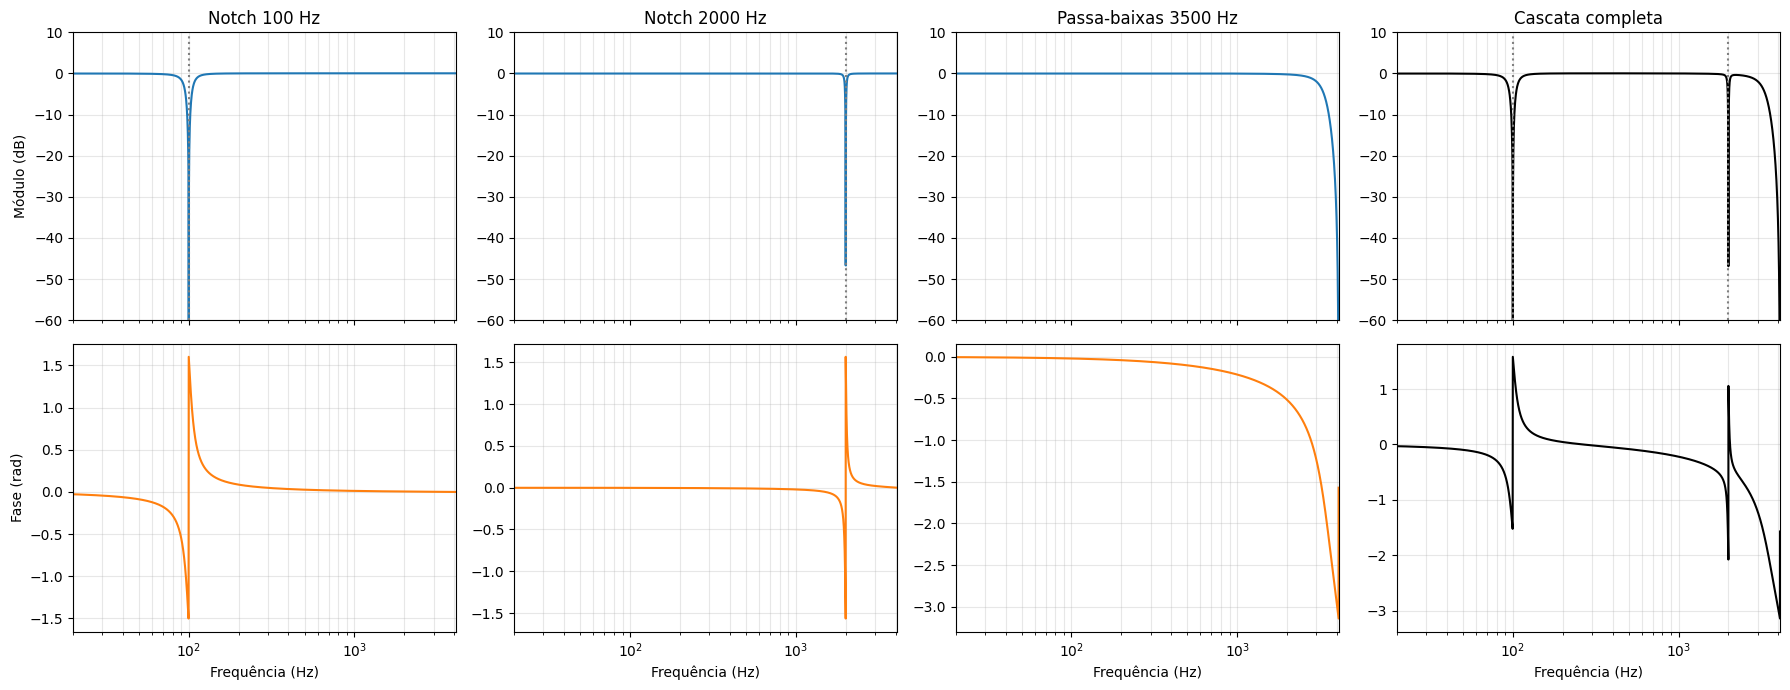

In [ ]:
R_LPF, FC_LPF = 0.6, 3500.0
blocos_audio = base + [projetar_bloco("lpf", FC_LPF, R_LPF, fs_a)]
nomes_blocos = ["Notch 100 Hz", "Notch 2000 Hz", "Passa-baixas 3500 Hz"]
sos_audio = sos_de(blocos_audio)
b_dir, a_dir = combinar_cascata(blocos_audio)            # filtro completo em forma direta (6ª ordem)

for nome, (b, a) in zip(nomes_blocos, blocos_audio):
    imprimir_hz(b, a, nome)
    z, p = zeros_polos(b, a)
    print(f"   polos: raio = {np.abs(p[0]):.4f}, ângulo = {np.degrees(np.angle(p[0])):.2f} graus (f = {np.angle(p[0])*fs_a/(2*np.pi):.1f} Hz);"
          f" zeros: raio = {np.round(np.abs(z), 3)}")
print(f"\nFiltro completo: ordem {len(a_dir)-1}, |polo|max = {np.max(np.abs(np.roots(a_dir))):.4f} (estável)")

F_A = np.linspace(0, fs_a / 2, 16384)
Hs_blocos = [resposta(b, a, F_A, fs_a) for b, a in blocos_audio]
H_total = np.prod(Hs_blocos, axis=0)
fig, eixos = plt.subplots(2, 4, figsize=(18, 7), sharex=True)
for j, (H, nome) in enumerate(zip(Hs_blocos + [H_total], nomes_blocos + ["Cascata completa"])):
    eixos[0, j].semilogx(F_A[1:], em_db(H[1:]), color="tab:blue" if j < 3 else "k")
    eixos[1, j].semilogx(F_A[1:], np.unwrap(np.angle(H[1:])), color="tab:orange" if j < 3 else "k")
    eixos[0, j].set_title(nome); eixos[0, j].set_ylim(-60, 10); eixos[0, j].grid(True, which="both", alpha=0.3)
    eixos[1, j].set_xlabel("Frequência (Hz)"); eixos[1, j].grid(True, which="both", alpha=0.3)
    eixos[0, j].axvline(100 if j in (0, 3) else np.nan, color="gray", ls=":"); eixos[0, j].axvline(2000 if j in (1, 3) else np.nan, color="gray", ls=":")
eixos[0, 0].set_ylabel("Módulo (dB)"); eixos[1, 0].set_ylabel("Fase (rad)")
eixos[0, 0].set_xlim(20, fs_a / 2)
plt.tight_layout(); plt.show()

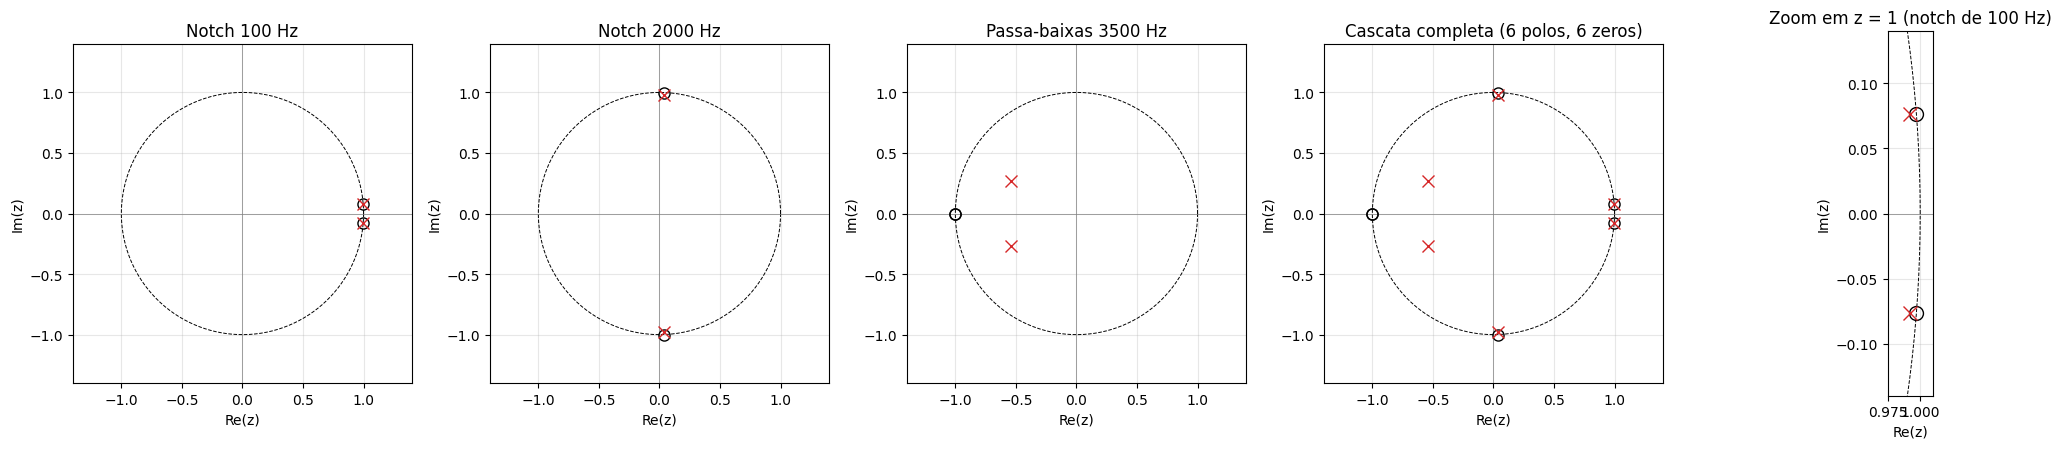

In [ ]:
fig, eixos = plt.subplots(1, 5, figsize=(21, 4.6))
theta = np.linspace(0, 2 * np.pi, 400)
for ax, (b, a), nome in zip(eixos[:3], blocos_audio, nomes_blocos):
    z, p = zeros_polos(b, a); desenhar_pz(ax, z, p); ax.set_title(nome); ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4)
z_t, p_t = zeros_polos(b_dir, a_dir)
desenhar_pz(eixos[3], z_t, p_t); eixos[3].set_title("Cascata completa (6 polos, 6 zeros)"); eixos[3].set_xlim(-1.4, 1.4); eixos[3].set_ylim(-1.4, 1.4)
desenhar_pz(eixos[4], z_t, p_t, ms=10); eixos[4].set_title("Zoom em z = 1 (notch de 100 Hz)")
eixos[4].set_xlim(0.975, 1.01); eixos[4].set_ylim(-0.14, 0.14)
plt.tight_layout(); plt.show()

### (d) Filtragem e comparação entre $x$, $y$ e $\hat x$

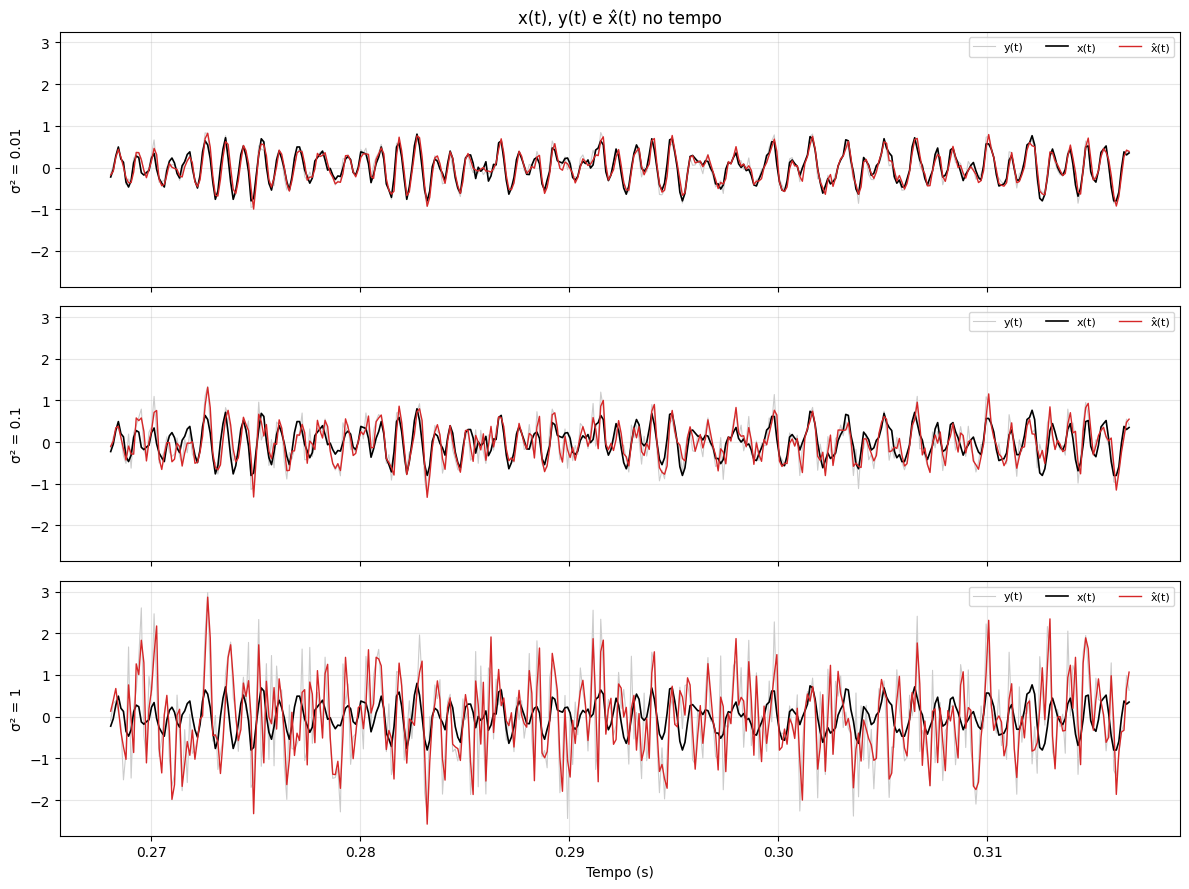

In [ ]:
x_hat = {s2: sosfilt(sos_audio, y_ruidoso[s2]) for s2 in SIGMA2}

fig, eixos = plt.subplots(3, 1, figsize=(12, 9), sharex=True, sharey=True)
for ax, s2 in zip(eixos, SIGMA2):
    ax.plot(t[janela], y_ruidoso[s2][janela], color="0.8", lw=0.8, label=f"y(t)")
    ax.plot(t[janela], x[janela], color="k", lw=1.2, label="x(t)")
    ax.plot(t[janela], x_hat[s2][janela], color="tab:red", lw=1.0, label="x̂(t)")
    ax.set_ylabel(f"σ² = {s2:g}"); ax.grid(True, alpha=0.3); ax.legend(fontsize=8, loc="upper right", ncol=3)
eixos[0].set_title("x(t), y(t) e x̂(t) no tempo")
eixos[-1].set_xlabel("Tempo (s)")
plt.tight_layout(); plt.show()

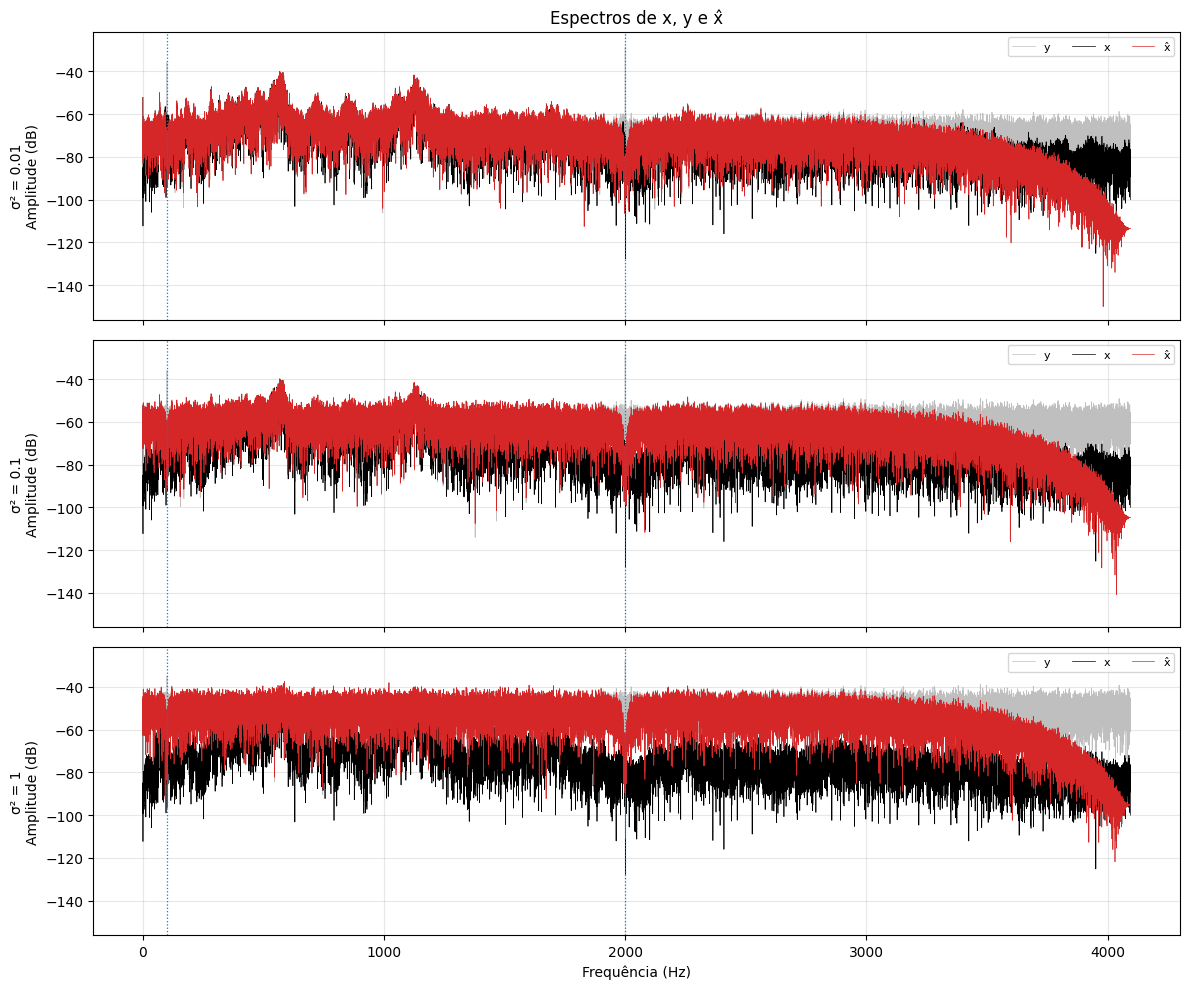

    σ² |  tom 100 Hz: y        x̂ |  tom 2000 Hz: y        x̂
  0.01 |        0.01625   0.00037 |         0.03667   0.00011
   0.1 |        0.01627   0.00086 |         0.03786   0.00028
     1 |        0.01816   0.00275 |         0.04162   0.00081


In [ ]:
fig, eixos = plt.subplots(3, 1, figsize=(12, 10), sharex=True, sharey=True)
for ax, s2 in zip(eixos, SIGMA2):
    f_y, a_y = calculate_spectrum(y_ruidoso[s2], fs_a)
    f_h, a_h = calculate_spectrum(x_hat[s2], fs_a)
    ax.plot(f_y, 20 * np.log10(a_y + 1e-12), color="0.75", lw=0.5, label="y")
    ax.plot(f_x, 20 * np.log10(a_x + 1e-12), color="k", lw=0.5, label="x")
    ax.plot(f_h, 20 * np.log10(a_h + 1e-12), color="tab:red", lw=0.5, label="x̂")
    for f0 in (F0_BAIXA, F0_ALTA):
        ax.axvline(f0, color="tab:blue", ls=":", lw=0.9)
    ax.set_ylabel(f"σ² = {s2:g}\nAmplitude (dB)"); ax.grid(True, alpha=0.3); ax.legend(fontsize=8, loc="upper right", ncol=3)
eixos[0].set_title("Espectros de x, y e x̂")
eixos[-1].set_xlabel("Frequência (Hz)")
plt.tight_layout(); plt.show()

# Amplitude dos tons antes e depois da filtragem
print(f"{'σ²':>6} | {'tom 100 Hz: y':>14} {'x̂':>9} | {'tom 2000 Hz: y':>15} {'x̂':>9}")
for s2 in SIGMA2:
    f_y, a_y = calculate_spectrum(y_ruidoso[s2], fs_a); f_h, a_h = calculate_spectrum(x_hat[s2], fs_a)
    print(f"{s2:6g} | {amplitude_pico(f_y, a_y, 100):14.5f} {amplitude_pico(f_h, a_h, 100):9.5f} | "
          f"{amplitude_pico(f_y, a_y, 2000):15.5f} {amplitude_pico(f_h, a_h, 2000):9.5f}")

### (e) Desempenho quantitativo

    σ² |  SNR in  SNR out   ΔSNR |   MSE in  MSE out |  P resíduo  P distorção | SNR out (só notches)  SNR out (fase zero)
  0.01 |    4.35     5.91   1.56 |   0.0141   0.0099 |     0.0073      0.00258 |                 5.86                 7.48
   0.1 |   -4.33    -2.91   1.42 |   0.1043   0.0752 |     0.0725      0.00258 |                -4.08                -2.32
     1 |  -14.17   -12.77   1.40 |   1.0052   0.7283 |     0.7254      0.00258 |               -14.08               -12.30

P_x = 0.03851. 'P resíduo' = potência de (interferências + ruído) após o filtro; 'P distorção' = potência de (H{x} - x).


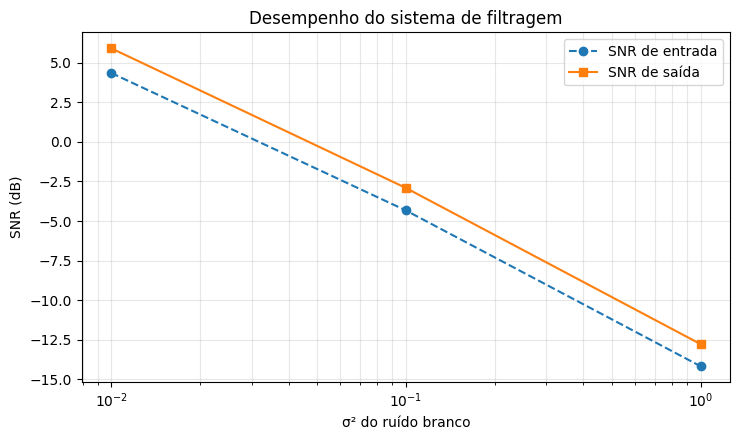

In [ ]:
sos_notches = sos_de(base)
print(f"{'σ²':>6} | {'SNR in':>7} {'SNR out':>8} {'ΔSNR':>6} | {'MSE in':>8} {'MSE out':>8} | {'P resíduo':>10} {'P distorção':>12} | {'SNR out (só notches)':>20} {'SNR out (fase zero)':>20}")
resultados_e = {}
for s2 in SIGMA2:
    y_ = y_ruidoso[s2]; e_ = y_ - x
    m = metricas_filtragem(sos_audio, x, y_, e_)
    m_n = metricas_filtragem(sos_notches, x, y_, e_)
    snr_fz = snr(x, sosfiltfilt(sos_audio, y_))
    resultados_e[s2] = m
    print(f"{s2:6g} | {m['snr_in']:7.2f} {m['snr_out']:8.2f} {m['snr_out']-m['snr_in']:6.2f} | {m['mse_in']:8.4f} {m['mse_out']:8.4f} | "
          f"{m['p_res']:10.4f} {m['p_dist']:12.5f} | {m_n['snr_out']:20.2f} {snr_fz:20.2f}")
print(f"\nP_x = {P(x):.5f}. 'P resíduo' = potência de (interferências + ruído) após o filtro; 'P distorção' = potência de (H{{x}} - x).")

plt.figure(figsize=(7.5, 4.5))
plt.semilogx(SIGMA2, [resultados_e[s]["snr_in"] for s in SIGMA2], "o--", label="SNR de entrada")
plt.semilogx(SIGMA2, [resultados_e[s]["snr_out"] for s in SIGMA2], "s-", label="SNR de saída")
plt.xlabel("σ² do ruído branco"); plt.ylabel("SNR (dB)")
plt.title("Desempenho do sistema de filtragem"); plt.grid(True, which="both", alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

### (f) Avaliação subjetiva (audição)

In [ ]:
print("Original:"); tocar(x, fs_a)
for s2 in SIGMA2:
    print(f"σ² = {s2:g} — contaminado:"); tocar(y_ruidoso[s2], fs_a)
    print(f"σ² = {s2:g} — recuperado:");  tocar(x_hat[s2], fs_a)

Original:


σ² = 0.01 — contaminado:


σ² = 0.01 — recuperado:


σ² = 0.1 — contaminado:


σ² = 0.1 — recuperado:


σ² = 1 — contaminado:


σ² = 1 — recuperado:


### (g) Quantização dos coeficientes ($b\in\{2,4,8,16\}$) e vantagens da cascata

Comparam-se (1) a **forma direta** do filtro completo (6ª ordem, polinômios $B(z)/A(z)$ quantizados) e (2) a **cascata**
de blocos de 2ª ordem quantizados individualmente. Além de $b\in\{2,4,8,16\}$, a tabela inclui 10 e 12 bits para
localizar o ponto a partir do qual cada estrutura se torna estável. O SNR é medido com $\sigma^2=0{,}1$; casos instáveis
não têm SNR definido.


In [ ]:
BITS_G = [2, 4, 8, 16]
BITS_G_TAB = [2, 4, 8, 10, 12, 16]
res_g = avaliar_quantizacao("cascata", blocos_audio, BITS_G_TAB, F_A, fs_a)
imprimir_tabela_quant(res_g, BITS_G_TAB)

# Faixa dinâmica dos coeficientes: forma direta x blocos
print("\nCoeficientes do denominador: forma direta a_1..a_6 =", np.round(a_dir[1:], 4))
for nome, (b, a) in zip(nomes_blocos, blocos_audio):
    print(f"   {nome}: a_1, a_2 = {np.round(a[1:], 6)}")

def snr_estrutura(res, bits, chave, y_, x_ref):
    r = res["bits"][bits][chave]
    if r["estado"] == "instável":
        return np.nan
    with np.errstate(all="ignore"):
        if chave == "direta":
            saida = lfilter(r["coef"][0], r["coef"][1], y_)
        else:
            saida = sosfilt(sos_de(r["coef"]), y_)
    return snr(x_ref, saida) if np.all(np.isfinite(saida)) else np.nan

ref_snr = {s2: resultados_e[s2]["snr_out"] for s2 in SIGMA2}
print("\n(* = polos em |z| = 1, estabilidade marginal)")
print(f"SNR de saída (dB) com coeficientes quantizados (referência sem quantização: " +
      ", ".join(f"σ²={s2:g}: {ref_snr[s2]:.2f}" for s2 in SIGMA2) + ")")
print(f"{'bits':>4} | " + " ".join(f"{'direta σ²='+format(s2,'g'):>16}" for s2 in SIGMA2) + " | " + " ".join(f"{'cascata σ²='+format(s2,'g'):>17}" for s2 in SIGMA2))
snr_g = {}
for bits in BITS_G_TAB:
    d = [snr_estrutura(res_g, bits, "direta", y_ruidoso[s2], x) for s2 in SIGMA2]
    c = [snr_estrutura(res_g, bits, "blocos", y_ruidoso[s2], x) for s2 in SIGMA2]
    snr_g[bits] = (d, c)
    fmt = lambda v, est: "instável" if np.isnan(v) else f"{v:.2f}" + ("*" if est == "marginal" else "")
    ed, ec = res_g["bits"][bits]["direta"]["estado"], res_g["bits"][bits]["blocos"]["estado"]
    print(f"{bits:4d} | " + " ".join(f"{fmt(v, ed):>16}" for v in d) + " | " + " ".join(f"{fmt(v, ec):>17}" for v in c))

bits | DIRETA |p|max  estável  erro (dB)  desl.polos  desl.zeros | BLOCOS |p|max  estável  erro (dB)  desl.polos  desl.zeros
   2 |        1.1915      NÃO     indef.      0.0767      0.0767 |        1.0000    marg.     indef.      0.5322      1.0000
   4 |        1.0000    marg.     indef.      0.0767      0.1449 |        1.0000    marg.     indef.      0.2676      0.5000
   8 |        0.9953      sim       14.9      0.0154      0.0548 |        1.0000    marg.     indef.      0.0766      0.0767
  10 |        0.9951      sim      -22.1      0.0005      0.0281 |        0.9941      sim       14.2      0.0142      0.0117
  12 |        0.9950      sim      -26.0      0.0003      0.0099 |        0.9951      sim      -32.4      0.0003      0.0001
  16 |        0.9950      sim      -55.2      0.0000      0.0035 |        0.9950      sim      -24.7      0.0003      0.0003

Coeficientes do denominador: forma direta a_1..a_6 = [-0.9795  0.2394 -0.4629 -0.4243  0.3121  0.3423]
   Notch 100 Hz: a_1,

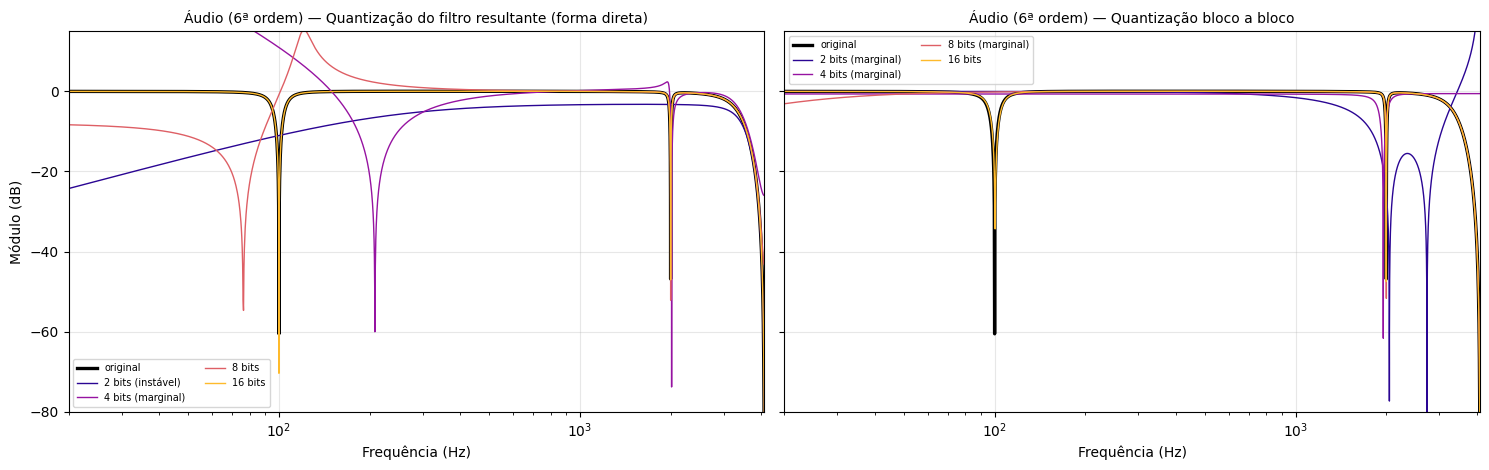

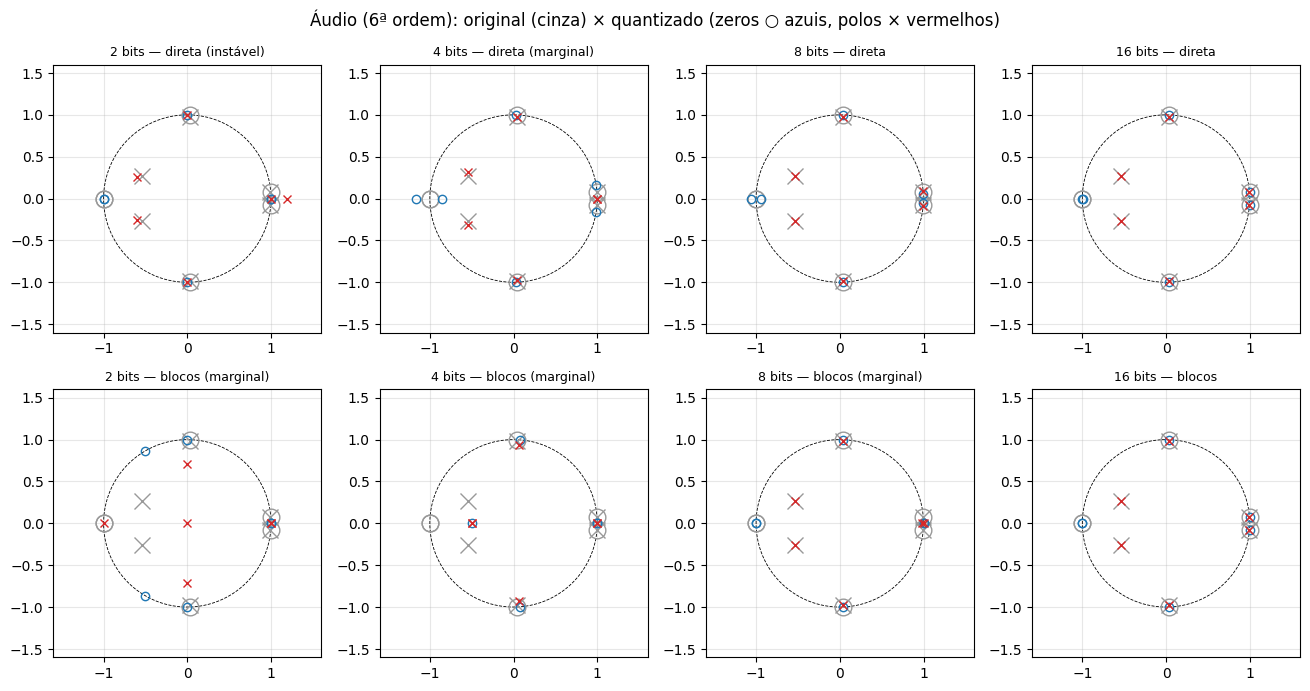

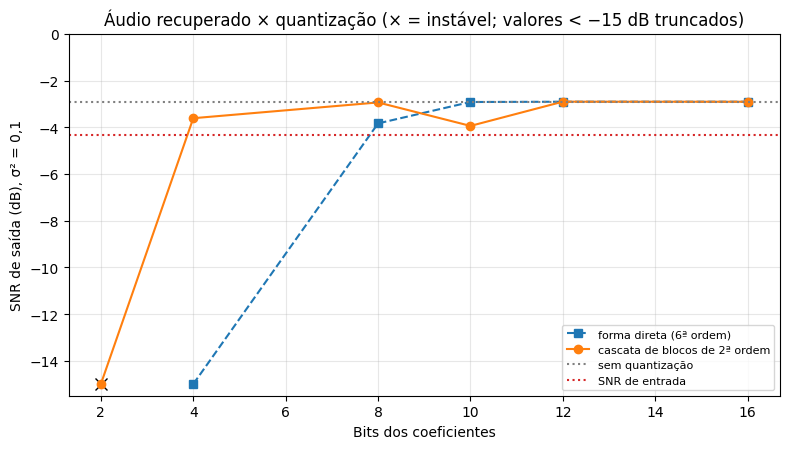

Cascata quantizada com 16 bits, σ² = 0,1:


In [ ]:
plotar_quant_resposta(res_g, BITS_G, F_A, "Áudio (6ª ordem)", ylim=(-80, 15), log_x=True)
plotar_quant_pz(res_g, BITS_G, "Áudio (6ª ordem)")

plt.figure(figsize=(8, 4.6))
idx01 = SIGMA2.index(0.1)
for chave, indice, estilo, nome in (("direta", 0, "s--", "forma direta (6ª ordem)"), ("blocos", 1, "o-", "cascata de blocos de 2ª ordem")):
    ys = np.array([snr_g[b][indice][idx01] for b in BITS_G_TAB])
    plt.plot(BITS_G_TAB, np.maximum(ys, -15.0), estilo, label=nome)      # valores < -15 dB truncados
    inst = np.isnan(ys)
    plt.plot(np.array(BITS_G_TAB)[inst], np.full(inst.sum(), -15.0), "x", color="k", ms=9)
plt.axhline(ref_snr[0.1], color="gray", ls=":", label="sem quantização")
plt.axhline(resultados_e[0.1]["snr_in"], color="tab:red", ls=":", label="SNR de entrada")
plt.xlabel("Bits dos coeficientes"); plt.ylabel("SNR de saída (dB), σ² = 0,1"); plt.ylim(-15.5, 0)
plt.title("Áudio recuperado × quantização (× = instável; valores < −15 dB truncados)"); plt.grid(True, alpha=0.3); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Cascata quantizada com 16 bits, σ² = 0,1:"); tocar(sosfilt(sos_de(res_g["bits"][16]["blocos"]["coef"]), y_ruidoso[0.1]), fs_a)